# All-Models Summary — no FS vs fsv3

4 models (GPT-4.1-mini, Gemini 2.5 Flash, Claude Haiku 4.5, Claude Opus 4.5) ×
5 datasets (SAGES, SAGES train, SAGES small, Endoscapes, Endo small).

Methods: Direct, CoT-first, Rubric, Rubric(w), Self-Rubric, SR-guided, SR-guided(w), SR-guided+s0fs, SR-guided+s0fs(w).

Uses `_runXXX` file discovery (non-copy directories).
Runs with similar line counts (min >= 90% of max) -> all runs (mean +/- std);
otherwise -> longest run only. Common-frame filtering within each model x dataset.

In [1]:
from __future__ import annotations

import json, re
from collections import defaultdict
from pathlib import Path
from typing import Dict, Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML
from sklearn.metrics import average_precision_score

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_rows', 200)

REPO_ROOT = Path('/shared_data0/weiqiuy/lvlm_cvs_reasoning').resolve()
OUTPUT_ROOT = REPO_ROOT / 'outputs' / 'rubric_oracle'
RUBRICS_PATH = REPO_ROOT / 'rubrics' / 'cvs_rubrics_v3.json'
CRITS = ['c1', 'c2', 'c3']
COMMON_ONLY = True
RUN_SIMILARITY_THRESHOLD = 0.9

SAGES_DIR      = OUTPUT_ROOT / 'manifests' / 'test_dev_dev'
ENDO_DIR       = OUTPUT_ROOT / 'manifests' / 'test_dev'
TRAIN_DIR      = OUTPUT_ROOT / 'manifests' / 'train_dev5'
SMALL_DIR      = OUTPUT_ROOT / 'manifests' / 'test_dev_dev_small'
ENDO_SMALL_DIR = OUTPUT_ROOT / 'manifests' / 'val_dev_small'

# ── Rubric weights ──
rubrics_data = json.loads(RUBRICS_PATH.read_text())
rubric_items: Dict[str, Dict[str, object]] = {}
for criterion, block in rubrics_data.get('criteria', {}).items():
    for item in block.get('items', []):
        item_id = item.get('id')
        if item_id:
            rubric_items[item_id] = {'criterion': criterion,
                                     'weight': float(item.get('weight', 0.0))}

def status_to_bin(s):
    return 1 if s == 'yes' else 0

def weighted_score_from_rubrics(pred_rubrics):
    """Weighted score: yes=1, uncertain/no=0."""
    totals, weights = {}, {}
    for item_id, status in pred_rubrics.items():
        meta = rubric_items.get(item_id)
        if not meta:
            continue
        c = str(meta['criterion']).lower()
        w = float(meta.get('weight', 0.0))
        totals[c] = totals.get(c, 0.0) + w * status_to_bin(status)
        weights[c] = weights.get(c, 0.0) + w
    return {c: (totals.get(c, 0.0) / weights[c] if weights.get(c, 0) else float('nan'))
            for c in CRITS}

def weighted_score_partial(pred_rubrics):
    """Weighted score with uncertain=0.5 (partial credit)."""
    totals, weights = {}, {}
    for item_id, status in pred_rubrics.items():
        meta = rubric_items.get(item_id)
        if not meta:
            continue
        c = str(meta['criterion']).lower()
        w = float(meta.get('weight', 0.0))
        if status == 'yes':
            totals[c] = totals.get(c, 0.0) + w * 1.0
        elif status == 'uncertain':
            totals[c] = totals.get(c, 0.0) + w * 0.5
        # 'no' contributes 0
        weights[c] = weights.get(c, 0.0) + w
    return {c: (totals.get(c, 0.0) / weights[c] if weights.get(c, 0) else float('nan'))
            for c in CRITS}

def last2_product_score(pred_rubrics):
    """Last-two-product formula per criterion.
    score = product(last 2 items) * mean(previous items).
    Values: yes=1, uncertain=0.5, no=0."""
    def _val(status):
        if status == 'yes':
            return 1.0
        if status == 'uncertain':
            return 0.5
        return 0.0

    # Group items by criterion, ordered by ID
    crit_items = {}
    for item_id, status in pred_rubrics.items():
        meta = rubric_items.get(item_id)
        if not meta:
            continue
        c = str(meta['criterion']).lower()
        crit_items.setdefault(c, []).append((item_id, status))

    result = {}
    for c in CRITS:
        items = crit_items.get(c, [])
        items.sort(key=lambda x: x[0])  # Sort by ID (C1-1, C1-2, ...)
        if len(items) < 3:
            result[c] = float('nan')
            continue
        last2_prod = _val(items[-2][1]) * _val(items[-1][1])
        prev = items[:-2]
        prev_mean = sum(_val(s) for _, s in prev) / len(prev)
        result[c] = last2_prod * prev_mean
    return result

# ── Utility functions ──
def iter_jsonl(path):
    with path.open('r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                yield json.loads(line)

def safe_ap(y_true, y_score):
    if len(set(y_true)) < 2:
        return float('nan')
    return float(average_precision_score(y_true, y_score))

def compute_ap(y_true, y_score):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    mask = ~np.isnan(y_score)
    y_true, y_score = y_true[mask], y_score[mask]
    if y_true.size == 0:
        return float('nan')
    return safe_ap(y_true.tolist(), y_score.tolist())

def fmt_pct(mean, std):
    if mean != mean:
        return '--'
    if std > 0:
        return f'{mean * 100:.1f} +/- {std * 100:.1f}'
    return f'{mean * 100:.1f}'

def parse_avg(s):
    if not s or s.startswith('--'):
        return float('nan'), 0.0
    parts = s.split('+/-')
    return float(parts[0].strip()), (float(parts[1].strip()) if len(parts) > 1 else 0.0)

print('Rubric items:', len(rubric_items))
for tag, d in [('SAGES', SAGES_DIR), ('Endoscapes', ENDO_DIR),
               ('SAGES train', TRAIN_DIR), ('SAGES small', SMALL_DIR),
               ('Endo small', ENDO_SMALL_DIR)]:
    print(f'  {tag}: {d}  (exists={d.exists()})')

Rubric items: 19
  SAGES: /shared_data0/weiqiuy/lvlm_cvs_reasoning/outputs/rubric_oracle/manifests/test_dev_dev  (exists=True)
  Endoscapes: /shared_data0/weiqiuy/lvlm_cvs_reasoning/outputs/rubric_oracle/manifests/test_dev  (exists=True)
  SAGES train: /shared_data0/weiqiuy/lvlm_cvs_reasoning/outputs/rubric_oracle/manifests/train_dev5  (exists=True)
  SAGES small: /shared_data0/weiqiuy/lvlm_cvs_reasoning/outputs/rubric_oracle/manifests/test_dev_dev_small  (exists=True)
  Endo small: /shared_data0/weiqiuy/lvlm_cvs_reasoning/outputs/rubric_oracle/manifests/val_dev_small  (exists=True)


In [2]:
# ── File discovery with _runXXX grouping and run filtering ──

FILENAME_RE = re.compile(
    r'^(?:endoscapes_val|cvs_challenge_sages_v1_val)__cvsrubricsv3__annv2__(.+)__seed13__([^/]+)\.jsonl$'
)
SUFFIX_RE = re.compile(r'(?:__\d{8}_\d{6}|_run\d{3})$')

def count_lines(path):
    with open(path) as f:
        return sum(1 for _ in f)

def discover_specs(root):
    """Discover output files, group by (model, exp_label).
    Strips _runXXX suffixes. Filters runs: if all runs have similar line counts
    (min >= threshold * max), keep all; otherwise keep only the longest."""
    if not root.exists():
        return []
    raw = []
    for fpath in sorted(root.rglob('*.jsonl')):
        if '_old' in fpath.name:
            continue
        match = FILENAME_RE.match(fpath.name)
        if not match:
            continue
        suffix, model_raw = match.groups()
        label = suffix.strip('_')
        model = SUFFIX_RE.sub('', model_raw)
        raw.append({'model': model, 'experiment_label': label, 'path': fpath})

    groups: dict[tuple, list[Path]] = defaultdict(list)
    for s in raw:
        groups[(s['model'], s['experiment_label'])].append(s['path'])

    specs = []
    for (m, e), ps in sorted(groups.items()):
        ps = sorted(ps)
        if len(ps) > 1:
            lc = [count_lines(p) for p in ps]
            mn, mx = min(lc), max(lc)
            if mx > 0 and mn >= RUN_SIMILARITY_THRESHOLD * mx:
                kept = ps
            else:
                best_idx = lc.index(max(lc))
                kept = [ps[best_idx]]
        else:
            kept = ps
        specs.append({'model': m, 'experiment_label': e, 'paths': kept,
                      'n_original': len(ps), 'n_kept': len(kept)})
    return specs

# ── Discover all 5 dataset directories ──
ALL_DIRS = [
    ('SAGES',        SAGES_DIR),
    ('Endoscapes',   ENDO_DIR),
    ('SAGES (train)', TRAIN_DIR),
    ('SAGES (small)', SMALL_DIR),
    ('Endo (small)', ENDO_SMALL_DIR),
]

all_specs = {}
for tag, d in ALL_DIRS:
    all_specs[tag] = discover_specs(d)
    print(f'{tag}: {len(all_specs[tag])} configs')

# Show relevant configs (no-fs and fsv3 only) for models of interest
MODELS_OF_INTEREST = {'gpt-4.1-mini', 'gemini-2.5-flash',
                      'claude-haiku-4-5-20251001', 'claude-opus-4-5-20251101'}
for tag, specs in all_specs.items():
    print(f'\n{tag}:')
    for s in specs:
        if s['model'] not in MODELS_OF_INTEREST:
            continue
        e = s['experiment_label']
        is_nofs = not any(x in e for x in ['fsv', 'fsd'])
        is_fsv3 = 'fsv3' in e and 'fsd' not in e
        is_sr = 'sr_guided' in e
        if is_nofs or is_fsv3 or is_sr:
            print(f"  {s['model']:40s}  {e:70s}  {s['n_kept']}/{s['n_original']} runs")

# ── Collect records ──

# All score types derived from rubric_labels_stage1
RUBRIC_SCORE_FUNCS = {
    'weighted':         weighted_score_from_rubrics,
    'weighted_partial': weighted_score_partial,
    'last2_product':    last2_product_score,
}

def collect_all_records(specs, dataset_tag):
    records = []
    for spec in specs:
        model, exp = spec['model'], spec['experiment_label']
        copy_counter = defaultdict(int)
        for fpath in spec['paths']:
            if not fpath.exists():
                continue
            for row in iter_jsonl(fpath):
                vid, fid = row.get('video_id', ''), row.get('frame_id', '')
                row_gt = row.get('gt')
                if not isinstance(row_gt, dict):
                    continue
                gt = {}
                for k in CRITS:
                    v = row_gt.get(k)
                    if v is not None:
                        gt[k] = 1 if float(v) > 0.5 else 0
                if not gt:
                    continue
                key = (vid, fid)
                ci = copy_counter[key]
                copy_counter[key] += 1
                fk = f'{vid}/{fid}'
                pred = row.get('pred', {}) or {}
                rubrics = row.get('rubric_labels_stage1', {}) or {}

                for c in CRITS:
                    gb = gt.get(c)
                    if gb is None:
                        continue
                    base = {'dataset': dataset_tag, 'model': model,
                            'experiment_label': exp, 'criterion': c,
                            'y_true': int(gb), 'file_name': fk,
                            'video_id': vid, 'frame_id': fid, 'copy_idx': ci}
                    # Direct (pred) score
                    ds = float(pred.get(c, float('nan')))
                    if ds == ds:
                        records.append({**base, 'score_type': 'direct', 'y_score': ds})
                    # All rubric-derived scores
                    if rubrics:
                        for stype, func in RUBRIC_SCORE_FUNCS.items():
                            sc = func(rubrics)
                            sv = float(sc.get(c, float('nan')))
                            if sv == sv:
                                records.append({**base, 'score_type': stype, 'y_score': sv})
    return pd.DataFrame(records)

all_dfs = {}
for tag, specs in all_specs.items():
    df = collect_all_records(specs, tag.lower().replace(' ', '_').replace('(', '').replace(')', ''))
    all_dfs[tag] = df
    print(f'{tag}: {len(df)} records')

# Backward-compatible names
df_sages = all_dfs['SAGES']
df_endo = all_dfs['Endoscapes']

SAGES: 50 configs
Endoscapes: 54 configs
SAGES (train): 128 configs
SAGES (small): 59 configs
Endo (small): 76 configs

SAGES:
  claude-haiku-4-5-20251001                 direct__preset-direct__test_dev_dev__critdef                            3/3 runs
  claude-haiku-4-5-20251001                 direct__preset-direct__test_dev_dev__critdef__fsv3__fs4                 3/3 runs
  claude-haiku-4-5-20251001                 direct__preset-direct__test_dev_dev__critdef__ratdf                     3/3 runs
  claude-haiku-4-5-20251001                 direct__preset-direct__test_dev_dev__critdef__ratdf__fsv3__fs4          3/3 runs
  claude-haiku-4-5-20251001                 predicted_only__test_dev_dev__critdef__fsv3__fs4                        3/3 runs
  claude-haiku-4-5-20251001                 self_rubric__test_dev_dev__critdef__rat1__s1short                       3/3 runs
  claude-haiku-4-5-20251001                 self_rubric__test_dev_dev__critdef__rat1__s1short__fsv3__fs4            3/3 run

In [3]:
# ── Evaluation helpers ──

def compute_method_stats(df, exp_label, model, score_type='direct'):
    """Compute per-criterion AP and average, with std across copies if >1."""
    mask = ((df['model'] == model) & (df['experiment_label'] == exp_label) &
            (df['score_type'] == score_type))
    sub = df[mask]
    nan_stat = (float('nan'), float('nan'))
    if sub.empty:
        return {c: nan_stat for c in CRITS}, nan_stat, []

    n_copies = sub['copy_idx'].max() + 1
    if n_copies > 1:
        per_copy_aps = {c: [] for c in CRITS}
        per_copy_n = []
        for ci in range(n_copies):
            cdf = sub[sub['copy_idx'] == ci]
            per_copy_n.append(cdf['file_name'].nunique())
            for c in CRITS:
                cs = cdf[cdf['criterion'] == c]
                per_copy_aps[c].append(compute_ap(cs['y_true'].values, cs['y_score'].values))
        crit_stats = {}
        for c in CRITS:
            valid = [a for a in per_copy_aps[c] if a == a]
            m = float(np.mean(valid)) if valid else float('nan')
            s = float(np.std(valid, ddof=1)) if len(valid) > 1 else 0.0
            crit_stats[c] = (m, s)
        per_copy_avg = [float(np.nanmean([per_copy_aps[c][ci] for c in CRITS]))
                        for ci in range(n_copies)]
        valid_avg = [a for a in per_copy_avg if a == a]
        avg_m = float(np.mean(valid_avg)) if valid_avg else float('nan')
        avg_s = float(np.std(valid_avg, ddof=1)) if len(valid_avg) > 1 else 0.0
        return crit_stats, (avg_m, avg_s), per_copy_n
    else:
        n_frames = [sub['file_name'].nunique()]
        crit_stats = {}
        for c in CRITS:
            cs = sub[sub['criterion'] == c]
            crit_stats[c] = (compute_ap(cs['y_true'].values, cs['y_score'].values), 0.0)
        avg_ap = float(np.nanmean([crit_stats[c][0] for c in CRITS]))
        return crit_stats, (avg_ap, 0.0), n_frames


def compute_binary_acc(y_true, y_score, threshold=0.5):
    """Compute binary accuracy: fraction of correct predictions at threshold."""
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    mask = ~np.isnan(y_score)
    y_true, y_score = y_true[mask], y_score[mask]
    if y_true.size == 0:
        return float('nan')
    y_pred = (y_score > threshold).astype(float)
    return float(np.mean(y_true == y_pred))


def compute_method_acc_stats(df, exp_label, model, score_type='direct'):
    """Compute per-criterion binary accuracy and average, with std across copies if >1."""
    mask = ((df['model'] == model) & (df['experiment_label'] == exp_label) &
            (df['score_type'] == score_type))
    sub = df[mask]
    nan_stat = (float('nan'), float('nan'))
    if sub.empty:
        return {c: nan_stat for c in CRITS}, nan_stat, []

    n_copies = sub['copy_idx'].max() + 1
    if n_copies > 1:
        per_copy_accs = {c: [] for c in CRITS}
        per_copy_n = []
        for ci in range(n_copies):
            cdf = sub[sub['copy_idx'] == ci]
            per_copy_n.append(cdf['file_name'].nunique())
            for c in CRITS:
                cs = cdf[cdf['criterion'] == c]
                per_copy_accs[c].append(compute_binary_acc(cs['y_true'].values, cs['y_score'].values))
        crit_stats = {}
        for c in CRITS:
            valid = [a for a in per_copy_accs[c] if a == a]
            m = float(np.mean(valid)) if valid else float('nan')
            s = float(np.std(valid, ddof=1)) if len(valid) > 1 else 0.0
            crit_stats[c] = (m, s)
        per_copy_avg = [float(np.nanmean([per_copy_accs[c][ci] for c in CRITS]))
                        for ci in range(n_copies)]
        valid_avg = [a for a in per_copy_avg if a == a]
        avg_m = float(np.mean(valid_avg)) if valid_avg else float('nan')
        avg_s = float(np.std(valid_avg, ddof=1)) if len(valid_avg) > 1 else 0.0
        return crit_stats, (avg_m, avg_s), per_copy_n
    else:
        n_frames = [sub['file_name'].nunique()]
        crit_stats = {}
        for c in CRITS:
            cs = sub[sub['criterion'] == c]
            crit_stats[c] = (compute_binary_acc(cs['y_true'].values, cs['y_score'].values), 0.0)
        avg_acc = float(np.nanmean([crit_stats[c][0] for c in CRITS]))
        return crit_stats, (avg_acc, 0.0), n_frames


def filter_common_frames(df, method_tuples, model):
    """Filter to common frames across all experiments for a given model.
    method_tuples: list of (name, nofs_exp, fs_exp, score_type).
    Uses union of frames across runs within each experiment, then intersects
    across experiments. Experiments with too few frames (< MIN_COMMON_RATIO of
    the largest experiment) are excluded from the intersection so they don't
    drag down the common set for other experiments.
    Keeps only the first copy (copy_idx=0) per frame so that incomplete runs
    don't shrink the common set."""
    if not COMMON_ONLY:
        return df
    all_exps = set()
    for _, nofs, fs, _ in method_tuples:
        if nofs:
            all_exps.add(nofs)
        if fs:
            all_exps.add(fs)

    exp_frame_sets = {}
    for exp in all_exps:
        mask = ((df['model'] == model) & (df['experiment_label'] == exp) &
                (df['score_type'] == 'direct'))
        sub = df[mask]
        if sub.empty:
            continue
        # Union of frames across all copies (runs)
        ef = set(sub['file_name'].unique())
        exp_frame_sets[exp] = ef

    if not exp_frame_sets:
        return df

    # Exclude experiments with too few frames from the intersection
    max_frames = max(len(fs) for fs in exp_frame_sets.values())
    kept_sets = []
    excluded_exps = []
    for exp, fs in exp_frame_sets.items():
        if len(fs) < MIN_COMMON_RATIO * max_frames:
            excluded_exps.append((exp, len(fs)))
        else:
            kept_sets.append(fs)

    if excluded_exps:
        for exp, n in excluded_exps:
            print(f'  EXCLUDED from common: {exp} ({n} frames, max={max_frames})')

    if not kept_sets:
        return df

    common = kept_sets[0]
    for fs in kept_sets[1:]:
        common &= fs

    # Keep only common frames, and only first copy (copy_idx=0) per frame
    # to avoid penalizing incomplete later runs
    rel = (df['model'] == model)
    keep = df['file_name'].isin(common) & (df['copy_idx'] == 0)
    df_out = df[~rel | (rel & keep)].copy()
    n_after = df_out[(df_out['model'] == model) &
                     (df_out['score_type'] == 'direct')]['file_name'].nunique()
    print(f'  COMMON: {len(common)} frames (first copy only), kept={n_after}')
    return df_out

print('Evaluation helpers ready.')

Evaluation helpers ready.


In [4]:
# ── Method configuration and evaluation ──

def make_method_tuples(split):
    """Returns list of (method_name, nofs_exp, fsv3_exp, score_type).
    Score types: direct, weighted (w), weighted_partial (p), last2_product (l2)."""
    rubric_exp = f'predicted_only__{split}__critdef__fsv3__fs4'
    sr_exp     = f'sr_guided__{split}__critdef__fsv3__fs4'
    sr_s0_exp  = f'sr_guided__s0fs__{split}__critdef__fsv3__fs4'
    return [
        ('Direct',
         f'direct__preset-direct__{split}__critdef',
         f'direct__preset-direct__{split}__critdef__fsv3__fs4',
         'direct'),
        ('CoT-first',
         f'direct__preset-direct__{split}__critdef__ratdf',
         f'direct__preset-direct__{split}__critdef__ratdf__fsv3__fs4',
         'direct'),
        # Rubric variants
        ('Rubric',         None, rubric_exp, 'direct'),
        ('Rubric(w)',      None, rubric_exp, 'weighted'),
        ('Rubric(p)',      None, rubric_exp, 'weighted_partial'),
        ('Rubric(l2)',     None, rubric_exp, 'last2_product'),
        # Self-Rubric
        ('Self-Rubric',
         f'self_rubric__{split}__critdef__rat1__s1short',
         f'self_rubric__{split}__critdef__rat1__s1short__fsv3__fs4',
         'direct'),
        # SR-guided variants
        ('SR-guided',         None, sr_exp, 'direct'),
        ('SR-guided(w)',      None, sr_exp, 'weighted'),
        ('SR-guided(p)',      None, sr_exp, 'weighted_partial'),
        ('SR-guided(l2)',     None, sr_exp, 'last2_product'),
        # SR-guided+s0fs variants
        ('SR-guided+s0fs',      None, sr_s0_exp, 'direct'),
        ('SR-guided+s0fs(w)',   None, sr_s0_exp, 'weighted'),
        ('SR-guided+s0fs(p)',   None, sr_s0_exp, 'weighted_partial'),
        ('SR-guided+s0fs(l2)', None, sr_s0_exp, 'last2_product'),
    ]

ALL_MODELS = [
    ('gpt-4.1-mini',              'GPT-4.1-mini'),
    ('gemini-2.5-flash',          'Gemini 2.5 Flash'),
    ('claude-haiku-4-5-20251001', 'Claude Haiku 4.5'),
    ('claude-opus-4-5-20251101',  'Claude Opus 4.5'),
]

DATASETS = [
    ('test_dev_dev',       'SAGES',         all_dfs['SAGES']),
    ('test_dev',           'Endoscapes',    all_dfs['Endoscapes']),
    ('train_dev5',         'SAGES (train)', all_dfs['SAGES (train)']),
    ('test_dev_dev_small', 'SAGES (small)', all_dfs['SAGES (small)']),
    ('val_dev_small',      'Endo (small)',  all_dfs['Endo (small)']),
]

MIN_COMMON_RATIO = 0.7  # blank out results if n_common < 70% of n_total

CRIT_NAMES = {'c1': 'Two Structures', 'c2': 'Clear Triangle', 'c3': 'Detachment'}

def parse_n_values(s):
    """Parse 'n1/n2/n3' string into list of ints."""
    if s == '--' or not s:
        return []
    return [int(x) for x in s.split('/')]

def should_blank(n_common_str, n_total_str):
    """Return True if n_common < MIN_COMMON_RATIO * n_total."""
    nc = parse_n_values(n_common_str)
    nt = parse_n_values(n_total_str)
    if not nc or not nt:
        return False
    avg_c = sum(nc) / len(nc)
    avg_t = sum(nt) / len(nt)
    return avg_t > 0 and avg_c < MIN_COMMON_RATIO * avg_t

def should_blank_vs_ref(n_total_str, ref_frames):
    """Return True if avg n_total < MIN_COMMON_RATIO * dataset reference frame count."""
    nt = parse_n_values(n_total_str)
    if not nt or ref_frames <= 0:
        return False
    avg_t = sum(nt) / len(nt)
    return avg_t < MIN_COMMON_RATIO * ref_frames

# ── Compute per-dataset reference frame counts (max across models) ──
dataset_ref_frames = {}
for split, dataset_name, df in DATASETS:
    max_frames = 0
    for model_id, _ in ALL_MODELS:
        sub = df[(df['model'] == model_id) & (df['score_type'] == 'direct')]
        if not sub.empty:
            n = sub[sub['copy_idx'] == 0]['file_name'].nunique()
            max_frames = max(max_frames, n)
    dataset_ref_frames[dataset_name] = max_frames
    print(f'Reference frames for {dataset_name}: {max_frames}')

# ── Evaluate all model × dataset combos ──

all_results = {}  # (model_id, dataset_name) -> rows

for model_id, model_name in ALL_MODELS:
    for split, dataset_name, df in DATASETS:
        method_tuples = make_method_tuples(split)
        key = (model_id, dataset_name)
        ref_frames = dataset_ref_frames.get(dataset_name, 0)

        sub = df[df['model'] == model_id]
        if sub.empty:
            display(HTML(f'<h3>{model_name} — {dataset_name}: <i>No data</i></h3>'))
            all_results[key] = []
            continue

        print(f'\n--- {model_name} / {dataset_name} ---')
        df_f = filter_common_frames(df, method_tuples, model_id)

        nan_stat = (float('nan'), float('nan'))
        rows = []
        for mname, nofs_exp, fs_exp, stype in method_tuples:
            row = {'Method': mname}

            # ── no FS ──
            if nofs_exp:
                nc_ap, na_ap, nn = compute_method_stats(df_f, nofs_exp, model_id, stype)
                _, _, nn_total = compute_method_stats(df, nofs_exp, model_id, stype)
                nc_acc, na_acc, _ = compute_method_acc_stats(df_f, nofs_exp, model_id, stype)
            else:
                nc_ap = nc_acc = {c: nan_stat for c in CRITS}
                na_ap = na_acc = nan_stat; nn = []; nn_total = []

            for c in CRITS:
                row[f'{c.upper()} AP (no FS)'] = fmt_pct(*nc_ap[c])
                row[f'{c.upper()} Acc (no FS)'] = fmt_pct(*nc_acc[c])
            row['Avg AP (no FS)'] = fmt_pct(*na_ap)
            row['Avg Acc (no FS)'] = fmt_pct(*na_acc)
            row['n_common (no FS)'] = '/'.join(str(x) for x in nn) if nn else '--'
            row['n_total (no FS)'] = '/'.join(str(x) for x in nn_total) if nn_total else '--'

            # Blank out no-FS results if common is too small vs total
            if (should_blank(row['n_common (no FS)'], row['n_total (no FS)']) or
                    should_blank_vs_ref(row['n_total (no FS)'], ref_frames)):
                for c in CRITS:
                    row[f'{c.upper()} AP (no FS)'] = '--*'
                    row[f'{c.upper()} Acc (no FS)'] = '--*'
                row['Avg AP (no FS)'] = '--*'
                row['Avg Acc (no FS)'] = '--*'

            # ── fsv3 ──
            if fs_exp:
                fc_ap, fa_ap, fn = compute_method_stats(df_f, fs_exp, model_id, stype)
                _, _, fn_total = compute_method_stats(df, fs_exp, model_id, stype)
                fc_acc, fa_acc, _ = compute_method_acc_stats(df_f, fs_exp, model_id, stype)
            else:
                fc_ap = fc_acc = {c: nan_stat for c in CRITS}
                fa_ap = fa_acc = nan_stat; fn = []; fn_total = []

            for c in CRITS:
                row[f'{c.upper()} AP (fsv3)'] = fmt_pct(*fc_ap[c])
                row[f'{c.upper()} Acc (fsv3)'] = fmt_pct(*fc_acc[c])
            row['Avg AP (fsv3)'] = fmt_pct(*fa_ap)
            row['Avg Acc (fsv3)'] = fmt_pct(*fa_acc)
            row['n_common (fsv3)'] = '/'.join(str(x) for x in fn) if fn else '--'
            row['n_total (fsv3)'] = '/'.join(str(x) for x in fn_total) if fn_total else '--'

            # Blank out fsv3 results if common is too small vs total
            if (should_blank(row['n_common (fsv3)'], row['n_total (fsv3)']) or
                    should_blank_vs_ref(row['n_total (fsv3)'], ref_frames)):
                for c in CRITS:
                    row[f'{c.upper()} AP (fsv3)'] = '--*'
                    row[f'{c.upper()} Acc (fsv3)'] = '--*'
                row['Avg AP (fsv3)'] = '--*'
                row['Avg Acc (fsv3)'] = '--*'

            rows.append(row)

        all_results[key] = rows
        df_rows = pd.DataFrame(rows)

        display(HTML(f'<h3>{model_name} — {dataset_name}</h3>'))

        # Accuracy table
        acc_cols = ['Method'] + \
            [f'{c.upper()} Acc (no FS)' for c in CRITS] + ['Avg Acc (no FS)'] + \
            ['n_common (no FS)', 'n_total (no FS)'] + \
            [f'{c.upper()} Acc (fsv3)' for c in CRITS] + ['Avg Acc (fsv3)'] + \
            ['n_common (fsv3)', 'n_total (fsv3)']
        display(HTML('<b>Binary Accuracy</b>'))
        display(df_rows[[c for c in acc_cols if c in df_rows.columns]])

        # mAP table
        ap_cols = ['Method'] + \
            [f'{c.upper()} AP (no FS)' for c in CRITS] + ['Avg AP (no FS)'] + \
            ['n_common (no FS)', 'n_total (no FS)'] + \
            [f'{c.upper()} AP (fsv3)' for c in CRITS] + ['Avg AP (fsv3)'] + \
            ['n_common (fsv3)', 'n_total (fsv3)']
        display(HTML('<b>mAP</b>'))
        display(df_rows[[c for c in ap_cols if c in df_rows.columns]])

print('\n--* = blanked because n_common < 70% of n_total or n_total < 70% of dataset max')
print('\nAll results computed.')

Reference frames for SAGES: 1350
Reference frames for Endoscapes: 791
Reference frames for SAGES (train): 90
Reference frames for SAGES (small): 95
Reference frames for Endo (small): 94

--- GPT-4.1-mini / SAGES ---
  EXCLUDED from common: sr_guided__test_dev_dev__critdef__fsv3__fs4 (510 frames, max=1350)
  COMMON: 1350 frames (first copy only), kept=1350


,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,40.5,53.9,84.0,59.5,1350,1350/1350/1350,56.7,55.7,85.2,65.9,1350,1350/1350/1350
1,CoT-first,38.8,61.9,87.3,62.7,1350,1350/1350/1350,63.6,63.9,77.5,68.3,1350,1350/1350/1350
2,Rubric,--,--,--,--,--,--,72.3,73.7,78.7,74.9,1350,1350/1350/1350
3,Rubric(w),--,--,--,--,--,--,72.3,73.4,78.7,74.8,1350,1350/1350/1350
4,Rubric(p),--,--,--,--,--,--,68.3,73.6,78.7,73.5,1350,1350/1350/1350
5,Rubric(l2),--,--,--,--,--,--,88.1,75.8,86.7,83.5,1350,1350/1350/1350
6,Self-Rubric,73.6,72.2,85.5,77.1,1350,1350/1350/1350,82.8,74.9,87.3,81.7,1350,1350/1350/1350
7,SR-guided,--,--,--,--,--,--,--*,--*,--*,--*,510,510
8,SR-guided(w),--,--,--,--,--,--,--*,--*,--*,--*,510,510
9,SR-guided(p),--,--,--,--,--,--,--*,--*,--*,--*,510,510


,Method,C1 AP (no FS),C2 AP (no FS),C3 AP (no FS),Avg AP (no FS),n_common (no FS),n_total (no FS),C1 AP (fsv3),C2 AP (fsv3),C3 AP (fsv3),Avg AP (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,14.2,31.1,12.2,19.2,1350,1350/1350/1350,14.0,29.9,12.7,18.9,1350,1350/1350/1350
1,CoT-first,16.9,30.9,11.4,19.7,1350,1350/1350/1350,17.2,31.0,12.8,20.3,1350,1350/1350/1350
2,Rubric,--,--,--,--,--,--,17.4,32.2,21.1,23.6,1350,1350/1350/1350
3,Rubric(w),--,--,--,--,--,--,17.8,33.2,22.0,24.3,1350,1350/1350/1350
4,Rubric(p),--,--,--,--,--,--,18.0,33.5,21.8,24.4,1350,1350/1350/1350
5,Rubric(l2),--,--,--,--,--,--,11.0,24.8,16.7,17.5,1350,1350/1350/1350
6,Self-Rubric,17.1,30.4,20.2,22.5,1350,1350/1350/1350,15.5,28.1,12.9,18.8,1350,1350/1350/1350
7,SR-guided,--,--,--,--,--,--,--*,--*,--*,--*,510,510
8,SR-guided(w),--,--,--,--,--,--,--*,--*,--*,--*,510,510
9,SR-guided(p),--,--,--,--,--,--,--*,--*,--*,--*,510,510



--- GPT-4.1-mini / Endoscapes ---
  COMMON: 623 frames (first copy only), kept=623


,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,41.3,46.2,56.2,47.9,623,791/791/791/791/791/791,45.6,38.2,54.3,46.0,623,791/791/791
1,CoT-first,41.3,45.9,57.3,48.2,623,791/791/791,68.7,61.2,57.5,62.4,623,791/791/791
2,Rubric,--,--,--,--,--,--,79.3,68.2,57.9,68.5,623,791/791/791
3,Rubric(w),--,--,--,--,--,--,79.3,65.7,57.9,67.6,623,791/791/791
4,Rubric(p),--,--,--,--,--,--,79.1,65.7,57.9,67.6,623,791/791/791
5,Rubric(l2),--,--,--,--,--,--,83.3,78.8,57.0,73.0,623,791/791/791
6,Self-Rubric,65.5,68.2,56.5,63.4,623,791/791/791,78.3,71.1,57.1,68.9,623,791/791/791
7,SR-guided,--,--,--,--,--,--,69.5,67.4,55.7,64.2,623,623
8,SR-guided(w),--,--,--,--,--,--,69.2,68.1,55.9,64.4,623,623
9,SR-guided(p),--,--,--,--,--,--,69.2,67.4,55.7,64.1,623,623


...

,Method,C1 AP (no FS),C2 AP (no FS),C3 AP (no FS),Avg AP (no FS),n_common (no FS),n_total (no FS),C1 AP (fsv3),C2 AP (fsv3),C3 AP (fsv3),Avg AP (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,18.5,29.1,54.1,33.9,95,95,23.8,37.6,44.8,35.4,95,95
1,CoT-first,21.6,30.9,54.5,35.7,95,95,22.0,33.9,59.7,38.5,95,95
2,Rubric,--,--,--,--,--,--,26.1,32.8,47.8,35.6,95,95
3,Rubric(w),--,--,--,--,--,--,25.8,33.2,40.6,33.2,95,95
4,Rubric(p),--,--,--,--,--,--,25.8,33.7,41.0,33.5,95,95
5,Rubric(l2),--,--,--,--,--,--,23.0,29.0,25.1,25.7,95,95
6,Self-Rubric,22.9,21.1,47.3,30.4,95,95,24.3,27.2,57.4,36.3,95,95
7,SR-guided,--,--,--,--,--,--,29.0,32.1,67.5,42.9,95,95
8,SR-guided(w),--,--,--,--,--,--,22.2,29.0,52.0,34.4,95,95
9,SR-guided(p),--,--,--,--,--,--,29.0,32.1,67.5,42.9,95,95



--- Claude Opus 4.5 / Endo (small) ---
  COMMON: 94 frames (first copy only), kept=94


,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,76.6,78.7,84.0,79.8,94,94,57.4,71.3,75.5,68.1,94,94
1,CoT-first,77.7,86.2,86.2,83.3,94,94,--*,--*,--*,--*,94,94/39/32
2,Rubric,--,--,--,--,--,--,67.0,74.5,58.5,66.7,94,94
3,Rubric(w),--,--,--,--,--,--,66.0,72.3,52.1,63.5,94,94
4,Rubric(p),--,--,--,--,--,--,66.0,72.3,52.1,63.5,94,94
5,Rubric(l2),--,--,--,--,--,--,78.7,81.9,83.0,81.2,94,94
6,Self-Rubric,85.1,84.0,88.3,85.8,94,94,84.0,85.1,90.4,86.5,94,94
7,SR-guided,--,--,--,--,--,--,84.0,85.1,74.5,81.2,94,94
8,SR-guided(w),--,--,--,--,--,--,85.1,85.1,85.1,85.1,94,94
9,SR-guided(p),--,--,--,--,--,--,80.9,85.1,74.5,80.1,94,94


,Method,C1 AP (no FS),C2 AP (no FS),C3 AP (no FS),Avg AP (no FS),n_common (no FS),n_total (no FS),C1 AP (fsv3),C2 AP (fsv3),C3 AP (fsv3),Avg AP (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,24.5,25.7,10.4,20.2,94,94,19.0,22.7,7.4,16.4,94,94
1,CoT-first,24.4,25.8,10.4,20.2,94,94,--*,--*,--*,--*,94,94/39/32
2,Rubric,--,--,--,--,--,--,16.5,15.2,9.2,13.6,94,94
3,Rubric(w),--,--,--,--,--,--,18.6,16.5,9.2,14.7,94,94
4,Rubric(p),--,--,--,--,--,--,18.6,16.4,9.2,14.7,94,94
5,Rubric(l2),--,--,--,--,--,--,16.2,17.0,10.3,14.5,94,94
6,Self-Rubric,32.0,23.5,13.4,23.0,94,94,18.5,19.9,16.8,18.4,94,94
7,SR-guided,--,--,--,--,--,--,26.0,26.8,16.0,23.0,94,94
8,SR-guided(w),--,--,--,--,--,--,26.4,26.8,16.1,23.1,94,94
9,SR-guided(p),--,--,--,--,--,--,26.0,26.8,16.0,23.0,94,94



--* = blanked because n_common < 70% of n_total or n_total < 70% of dataset max

All results computed.


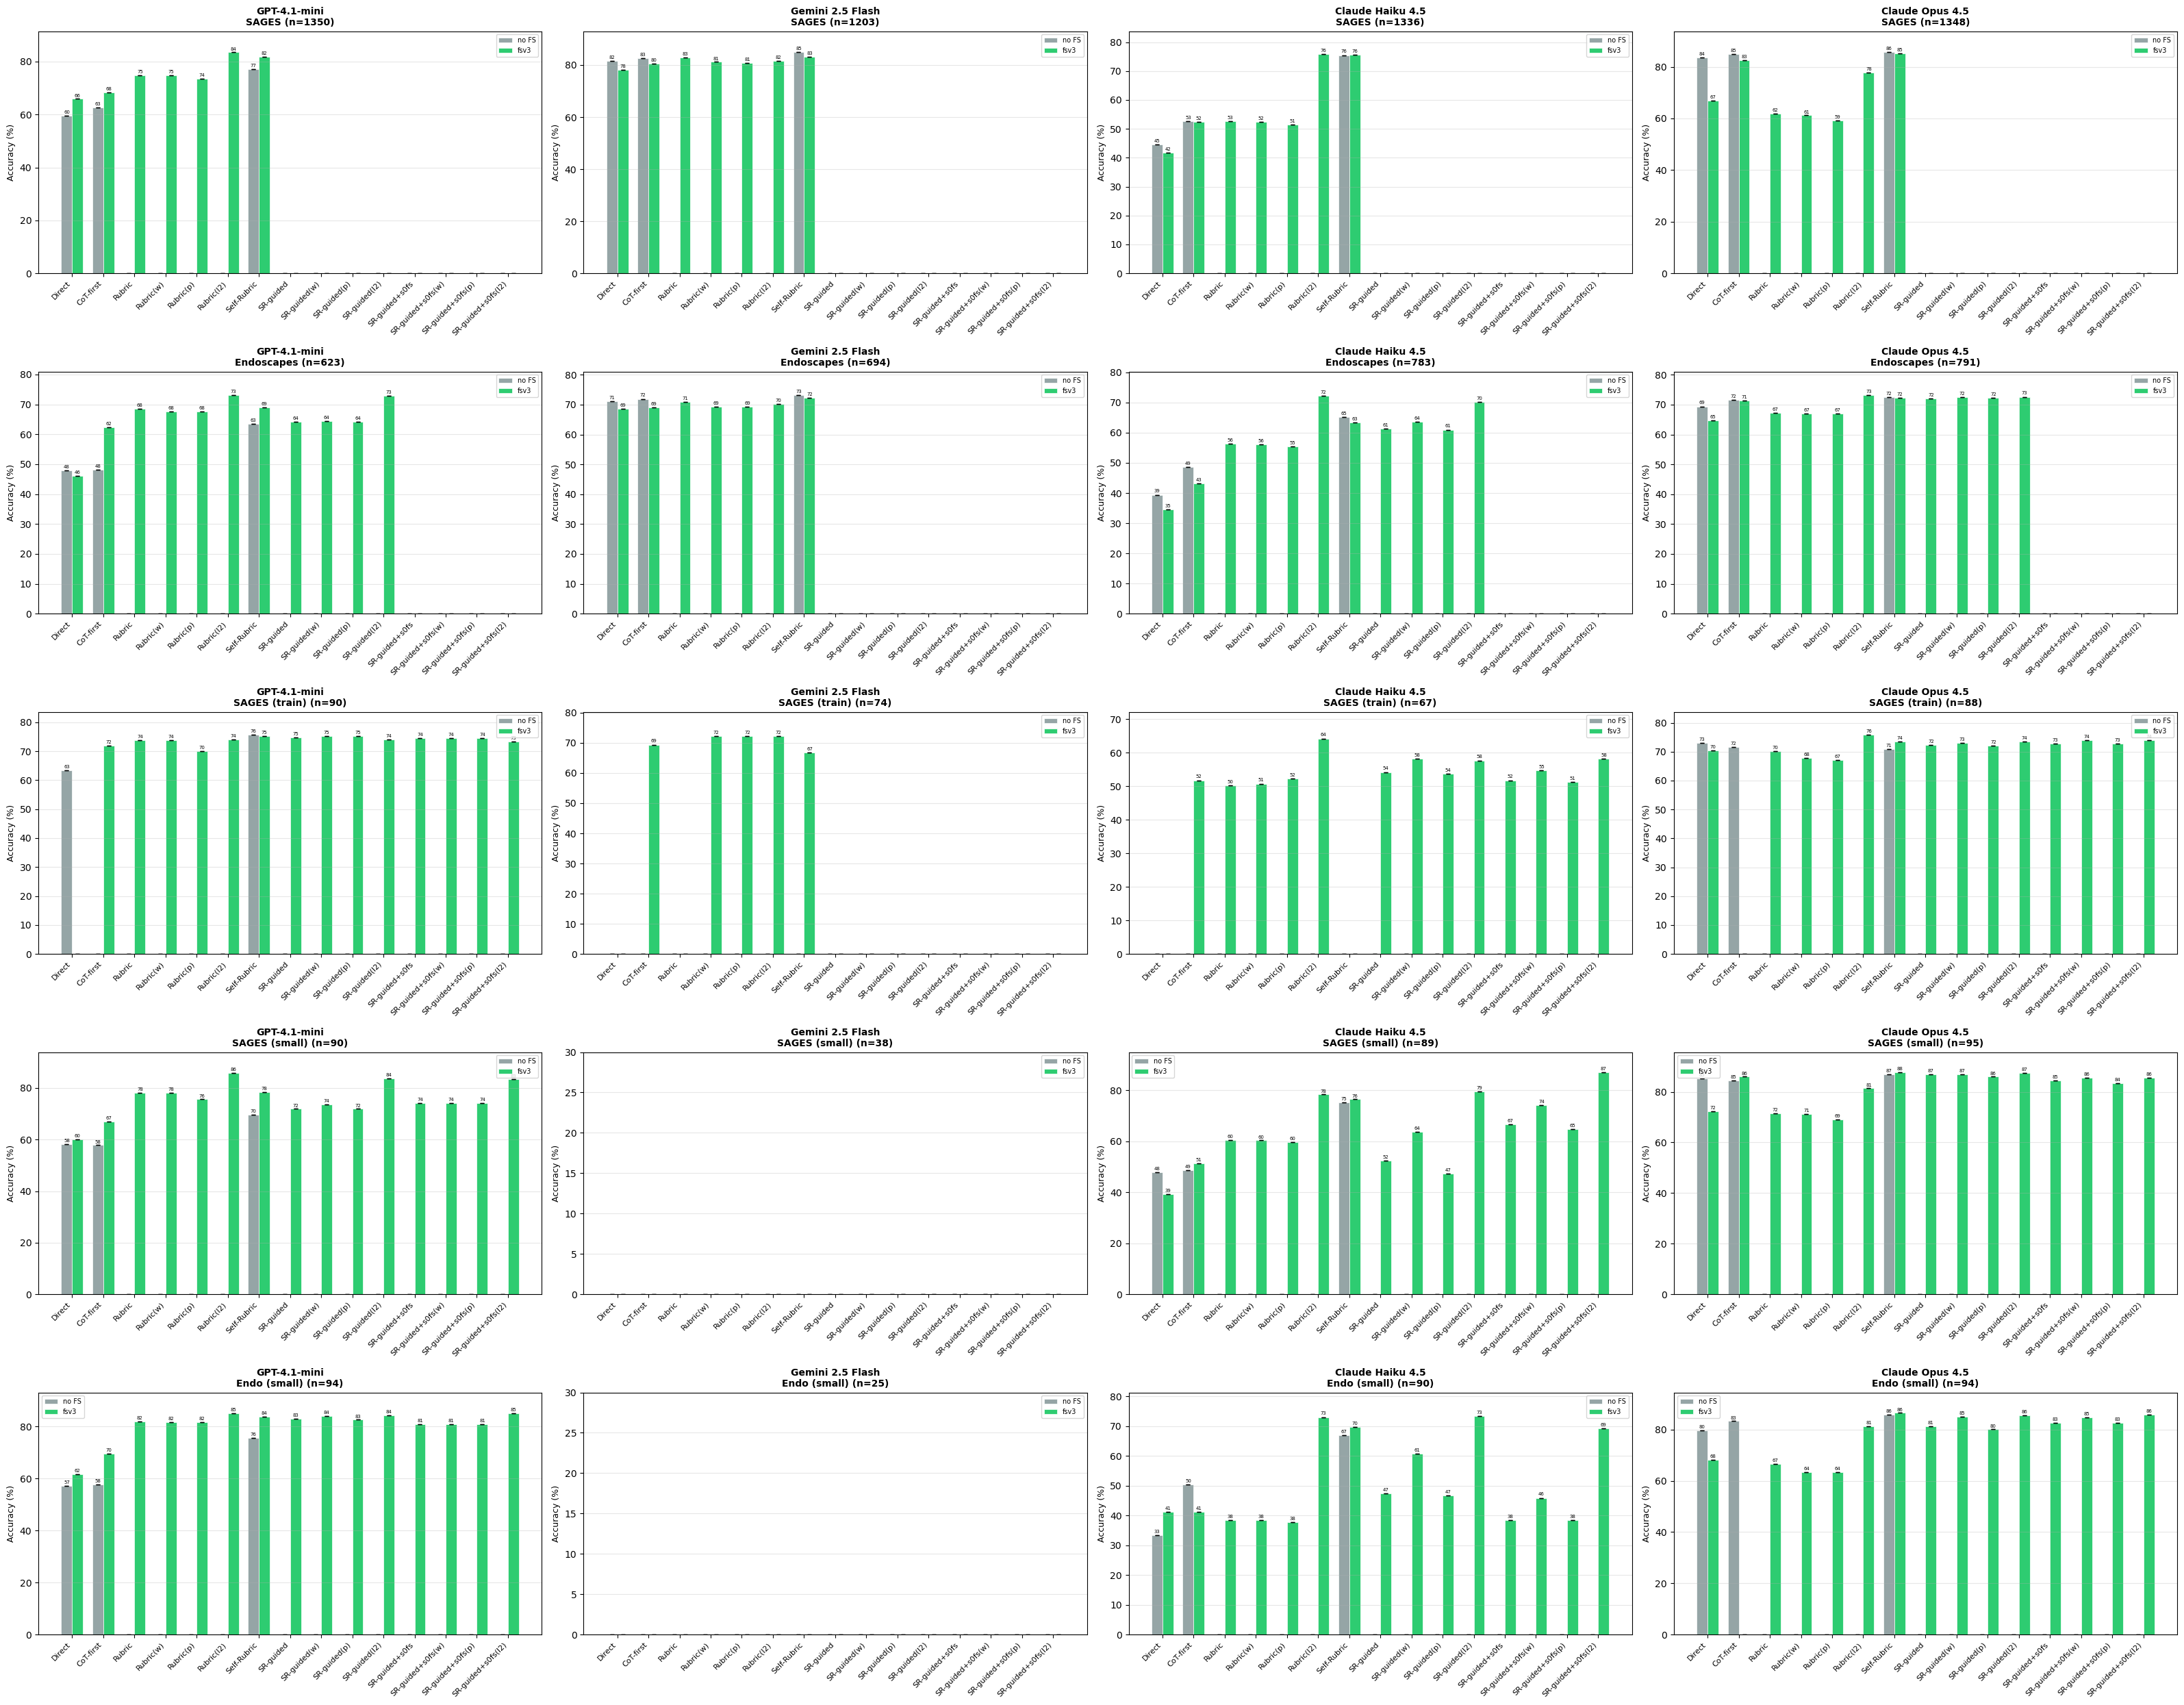

Saved: all_models_summary_new_accuracy.pdf


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,65.9,56.7,55.7,85.2,68.3,63.6,63.9,77.5,74.9,72.3,73.7,78.7,74.8,72.3,73.4,78.7,73.5,68.3,73.6,78.7,83.5,88.1,75.8,86.7,...,--*,--*,--*,--*,--*,--*,--*,--*,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,83.5 (Rubric(l2))
1,Gemini 2.5 Flash,78.1,85.0,77.2,72.1,80.5,88.2,77.9,75.5,82.8,88.3,78.2,81.9,81.2,88.3,77.6,77.9,80.9,87.7,77.5,77.6,81.7,88.3,78.2,78.6,...,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,83.1 (Self-Rubric)
2,Claude Haiku 4.5,41.7,15.6,28.3,81.3,52.5,38.9,51.2,67.3,52.6,65.6,60.5,31.7,52.4,65.6,60.0,31.6,51.4,63.8,58.8,31.5,75.8,81.1,71.5,74.9,...,--*,--*,--*,--*,--*,--*,--*,--*,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,75.8 (Rubric(l2))
3,Claude Opus 4.5,67.0,59.1,73.2,68.6,82.6,82.9,77.4,87.4,61.8,72.7,71.1,41.5,61.2,72.6,71.0,40.1,59.3,67.2,70.5,40.1,77.7,79.5,74.0,79.6,...,--*,--*,--*,--*,--*,--*,--*,--*,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,85.2 (Self-Rubric)


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,46.0,45.6,38.2,54.3,62.4,68.7,61.2,57.5,68.5,79.3,68.2,57.9,67.6,79.3,65.7,57.9,67.6,79.1,65.7,57.9,73.0,83.3,78.8,57.0,...,64.1,69.2,67.4,55.7,72.8,80.4,80.6,57.3,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,73.0 (Rubric(l2))
1,Gemini 2.5 Flash,68.6,76.7,76.2,53.0,69.1,75.4,77.7,54.2,70.9,78.0,79.8,54.9,69.3,77.5,77.2,53.0,69.2,77.4,77.2,53.0,70.2,78.0,78.8,53.9,...,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,72.3 (Self-Rubric)
2,Claude Haiku 4.5,34.6,24.3,24.8,54.7,43.1,30.9,47.6,50.6,56.3,63.6,58.6,46.7,56.1,63.3,58.4,46.5,55.4,61.3,58.4,46.5,72.3,80.2,76.8,60.0,...,61.0,63.3,71.0,48.7,70.2,78.0,76.6,56.1,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,72.3 (Rubric(l2))
3,Claude Opus 4.5,64.6,65.9,74.7,53.1,71.3,77.6,79.8,56.4,67.3,74.5,77.2,50.2,66.9,72.8,77.2,50.7,67.0,72.8,77.2,50.8,73.1,80.5,81.3,57.5,...,72.2,80.4,80.2,56.0,72.6,80.7,80.3,56.8,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,73.1 (Rubric(l2))


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,--,--,--,--,71.9,77.8,63.3,74.4,73.7,83.3,61.1,76.7,73.7,83.3,61.1,76.7,70.0,72.2,61.1,76.7,74.1,81.1,63.3,77.8,...,75.2,84.4,65.6,75.6,74.1,81.1,62.2,78.9,74.4,83.3,62.2,77.8,74.4,83.3,62.2,77.8,74.4,83.3,62.2,77.8,73.3,80.0,62.2,77.8,75.2 (Self-Rubric)
1,Gemini 2.5 Flash,--,--,--,--,69.4,77.0,59.5,71.6,--*,--*,--*,--*,72.3,79.2,66.0,71.7,72.3,79.2,66.0,71.7,72.3,79.2,66.0,71.7,...,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,72.3 (Rubric(w))
2,Claude Haiku 4.5,--,--,--,--,51.7,55.2,40.3,59.7,50.2,55.2,47.8,47.8,50.7,55.2,49.3,47.8,52.2,55.2,52.2,49.3,64.2,67.2,53.7,71.6,...,53.7,56.7,49.3,55.2,57.7,59.7,46.3,67.2,51.7,61.2,44.8,49.3,54.7,59.7,43.3,61.2,51.2,59.7,44.8,49.3,58.2,61.2,43.3,70.1,64.2 (Rubric(l2))
3,Claude Opus 4.5,70.5,75.0,62.5,73.9,--*,--*,--*,--*,70.1,79.5,68.2,62.5,67.8,79.5,67.0,56.8,67.0,76.1,68.2,56.8,75.8,79.5,67.0,80.7,...,72.0,77.3,60.2,78.4,73.5,79.5,61.4,79.5,72.7,78.4,62.5,77.3,73.9,80.7,61.4,79.5,72.7,78.4,62.5,77.3,73.9,80.7,61.4,79.5,75.8 (Rubric(l2))


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,60.0,44.4,54.4,81.1,67.0,58.9,65.6,76.7,78.1,68.9,73.3,92.2,78.1,68.9,73.3,92.2,75.6,64.4,70.0,92.2,85.9,90.0,82.2,85.6,...,71.9,67.8,72.2,75.6,83.7,87.8,81.1,82.2,74.1,71.1,71.1,80.0,74.1,71.1,71.1,80.0,74.1,71.1,71.1,80.0,83.3,87.8,81.1,81.1,85.9 (Rubric(l2))
1,Gemini 2.5 Flash,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,...,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--
2,Claude Haiku 4.5,39.3,18.0,22.5,77.5,51.3,40.4,46.1,67.4,60.5,72.4,64.4,44.8,60.3,73.0,62.9,44.9,59.6,73.0,61.8,43.8,78.3,86.5,77.5,70.8,...,47.2,40.4,53.9,47.2,79.4,80.9,83.1,74.2,66.7,73.0,73.0,53.9,74.2,85.4,74.2,62.9,64.8,67.4,73.0,53.9,86.9,92.1,87.6,80.9,86.9 (SR-guided+s0fs(l2))
3,Claude Opus 4.5,72.3,60.0,81.1,75.8,86.0,86.3,86.3,85.3,71.6,78.9,76.8,58.9,71.2,78.9,75.8,58.9,69.1,74.7,73.7,58.9,81.4,84.2,84.2,75.8,...,86.0,86.3,84.2,87.4,87.4,92.6,87.4,82.1,84.6,83.2,83.2,87.4,85.6,85.3,83.2,88.4,83.5,80.0,83.2,87.4,85.6,87.4,88.4,81.1,87.7 (Self-Rubric)


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,61.7,54.3,45.7,85.1,69.5,69.1,62.8,76.6,81.9,89.4,76.6,79.8,81.6,89.4,75.5,79.8,81.6,89.4,75.5,79.8,85.1,88.3,81.9,85.1,...,82.6,79.8,77.7,90.4,84.4,81.9,79.8,91.5,80.9,76.6,73.4,92.6,80.9,76.6,73.4,92.6,80.9,76.6,73.4,92.6,85.1,81.9,80.9,92.6,85.1 (Rubric(l2))
1,Gemini 2.5 Flash,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,...,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--
2,Claude Haiku 4.5,41.1,15.6,18.9,88.9,41.1,25.6,37.8,60.0,38.5,51.1,47.8,16.7,38.5,51.1,47.8,16.7,37.8,48.9,47.8,16.7,73.0,75.6,73.3,70.0,...,46.7,37.8,62.2,40.0,73.3,74.4,76.7,68.9,38.5,34.4,47.8,33.3,45.9,48.9,47.8,41.1,38.5,34.4,47.8,33.3,69.3,72.2,70.0,65.6,73.3 (SR-guided(l2))
3,Claude Opus 4.5,68.1,57.4,71.3,75.5,--*,--*,--*,--*,66.7,67.0,74.5,58.5,63.5,66.0,72.3,52.1,63.5,66.0,72.3,52.1,81.2,78.7,81.9,83.0,...,80.1,80.9,85.1,74.5,85.5,85.1,85.1,86.2,82.6,80.9,86.2,80.9,84.8,81.9,86.2,86.2,82.6,80.9,86.2,80.9,85.8,83.0,86.2,88.3,86.5 (Self-Rubric)


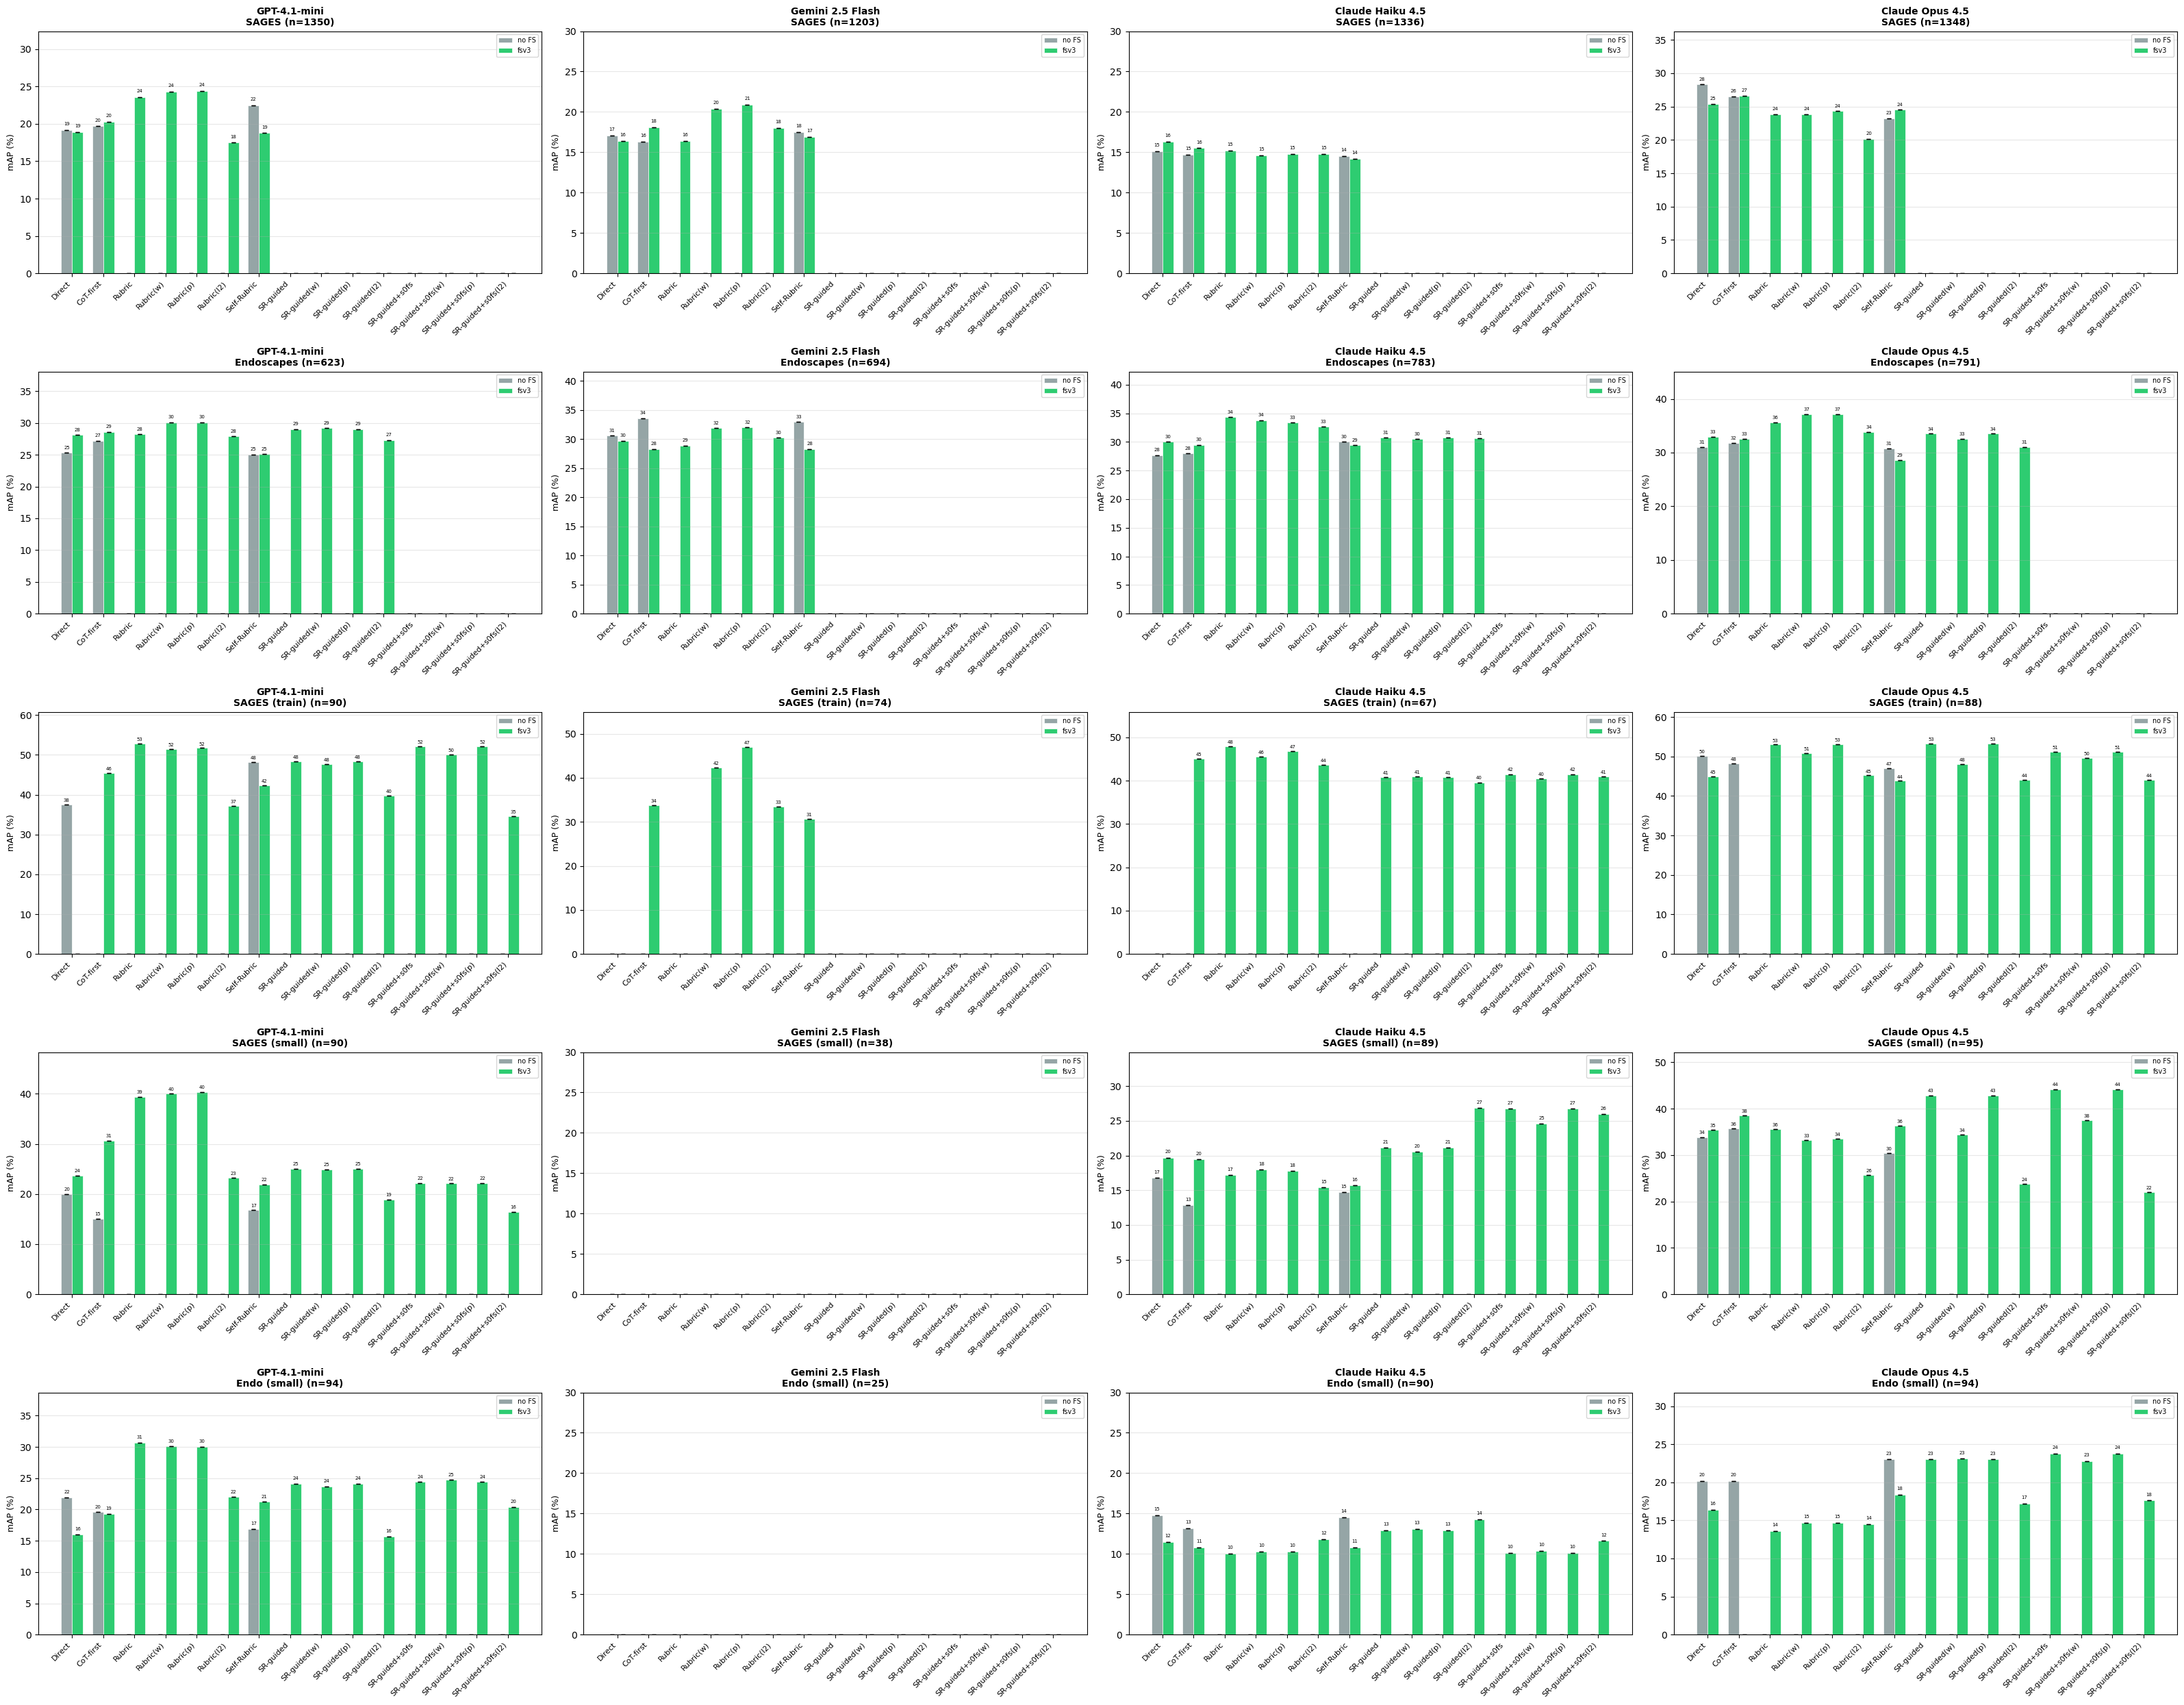

Saved: all_models_summary_new_map.pdf


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,18.9,14.0,29.9,12.7,20.3,17.2,31.0,12.8,23.6,17.4,32.2,21.1,24.3,17.8,33.2,22.0,24.4,18.0,33.5,21.8,17.5,11.0,24.8,16.7,...,--*,--*,--*,--*,--*,--*,--*,--*,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,24.4 (Rubric(p))
1,Gemini 2.5 Flash,16.4,12.1,26.7,10.6,18.1,15.0,27.3,11.9,16.4,12.3,25.9,11.0,20.4,16.2,33.4,11.6,20.9,17.3,33.8,11.6,18.0,14.3,28.5,11.1,...,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,20.9 (Rubric(p))
2,Claude Haiku 4.5,16.3,8.9,23.7,16.2,15.5,8.4,21.7,16.4,15.2,9.1,22.7,13.9,14.6,8.9,22.3,12.7,14.8,8.9,22.4,13.0,14.8,9.0,23.3,12.2,...,--*,--*,--*,--*,--*,--*,--*,--*,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,16.3 (Direct)
3,Claude Opus 4.5,25.4,16.9,35.1,24.3,26.6,17.6,35.4,26.7,23.8,16.9,29.7,24.6,23.8,16.0,32.1,23.1,24.3,16.8,32.9,23.0,20.1,14.3,28.0,18.0,...,--*,--*,--*,--*,--*,--*,--*,--*,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,26.6 (CoT-first)


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,28.1,23.3,20.6,40.5,28.6,23.5,18.9,43.4,28.2,22.5,18.2,43.9,30.1,26.2,19.4,44.7,30.1,26.1,19.4,44.7,27.9,24.3,17.0,42.4,...,29.0,22.3,22.2,42.4,27.3,22.5,17.3,42.2,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,30.1 (Rubric(w))
1,Gemini 2.5 Flash,29.7,23.3,21.7,43.9,28.3,19.3,20.6,44.9,28.9,19.7,22.7,44.3,31.9,23.3,27.7,44.8,32.0,23.5,27.7,44.8,30.2,20.9,25.1,44.5,...,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,32.0 (Rubric(p))
2,Claude Haiku 4.5,30.0,21.1,21.6,47.3,29.5,22.2,23.5,42.9,34.3,29.1,24.3,49.6,33.8,29.0,23.9,48.6,33.4,27.9,23.8,48.6,32.7,27.7,22.4,47.9,...,30.8,24.9,24.2,43.4,30.6,24.3,21.6,45.8,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,34.3 (Rubric)
3,Claude Opus 4.5,32.9,28.0,26.9,43.7,32.6,27.8,26.5,43.5,35.6,29.6,30.4,46.7,37.1,31.1,33.4,46.8,37.1,31.1,33.4,47.0,33.8,26.1,29.8,45.6,...,33.5,27.4,27.3,45.8,31.0,20.7,25.8,46.6,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,37.1 (Rubric(w))


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,--,--,--,--,45.5,53.9,58.1,24.3,52.8,64.2,62.2,32.0,51.5,58.3,60.5,35.7,51.7,58.1,61.2,35.7,37.1,37.6,51.5,22.2,...,48.4,62.8,55.0,27.4,39.8,39.2,50.1,30.0,52.1,57.2,56.0,43.1,50.1,52.3,55.0,43.1,52.1,57.2,56.0,43.1,34.6,34.3,45.9,23.6,52.8 (Rubric)
1,Gemini 2.5 Flash,--,--,--,--,33.8,34.2,41.7,25.4,--*,--*,--*,--*,42.3,44.8,57.6,24.6,47.0,56.5,59.5,25.1,33.4,38.6,39.1,22.5,...,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,47.0 (Rubric(p))
2,Claude Haiku 4.5,--,--,--,--,45.1,48.8,52.8,33.6,47.9,42.8,53.6,47.4,45.5,38.4,56.1,42.0,46.8,42.1,56.6,41.7,43.7,35.1,55.5,40.6,...,40.8,37.4,47.8,37.4,39.6,32.9,49.0,36.8,41.5,39.3,46.1,39.0,40.5,34.7,46.8,40.0,41.5,39.3,46.1,39.0,41.0,35.9,48.0,39.1,47.9 (Rubric)
3,Claude Opus 4.5,45.0,43.9,62.9,28.2,--*,--*,--*,--*,53.0,52.7,62.9,43.6,50.9,47.3,61.5,43.9,53.1,49.9,63.1,46.2,45.2,41.7,54.4,39.5,...,53.3,51.0,63.3,45.5,44.0,34.7,47.8,49.6,51.1,51.6,61.5,40.3,49.6,42.5,62.7,43.6,51.1,51.6,61.5,40.3,44.1,38.4,49.9,43.9,53.3 (SR-guided)


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,23.7,11.9,30.8,28.3,30.6,31.6,30.6,29.6,39.4,19.0,23.7,75.4,40.0,18.0,23.3,78.5,40.3,18.0,24.2,78.5,23.2,8.9,14.0,46.7,...,25.0,13.9,24.2,37.0,18.9,8.9,14.5,33.3,22.2,14.9,21.0,30.6,22.1,14.9,20.9,30.6,22.2,14.9,21.0,30.6,16.4,6.7,12.4,30.2,40.3 (Rubric(p))
1,Gemini 2.5 Flash,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,...,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--
2,Claude Haiku 4.5,19.7,6.5,10.0,42.5,19.5,12.8,13.8,31.8,17.2,13.9,11.6,26.2,18.0,16.6,13.1,24.2,17.8,15.7,13.5,24.2,15.4,11.2,12.5,22.4,...,21.1,13.4,19.4,30.5,26.9,19.8,23.7,37.1,26.8,25.8,21.7,32.9,24.6,21.1,21.6,31.3,26.8,25.8,21.7,32.9,26.0,22.8,20.7,34.4,26.9 (SR-guided(l2))
3,Claude Opus 4.5,35.4,23.8,37.6,44.8,38.5,22.0,33.9,59.7,35.6,26.1,32.8,47.8,33.2,25.8,33.2,40.6,33.5,25.8,33.7,41.0,25.7,23.0,29.0,25.1,...,42.9,29.0,32.1,67.5,23.8,20.9,15.4,35.0,44.2,21.8,37.0,73.8,37.5,12.3,35.4,64.9,44.2,21.8,37.0,73.8,22.0,10.9,25.2,30.0,44.2 (SR-guided+s0fs)


,Model,Direct Avg,Direct C1,Direct C2,Direct C3,CoT-first Avg,CoT-first C1,CoT-first C2,CoT-first C3,Rubric Avg,Rubric C1,Rubric C2,Rubric C3,Rubric(w) Avg,Rubric(w) C1,Rubric(w) C2,Rubric(w) C3,Rubric(p) Avg,Rubric(p) C1,Rubric(p) C2,Rubric(p) C3,Rubric(l2) Avg,Rubric(l2) C1,Rubric(l2) C2,Rubric(l2) C3,...,SR-guided(p) Avg,SR-guided(p) C1,SR-guided(p) C2,SR-guided(p) C3,SR-guided(l2) Avg,SR-guided(l2) C1,SR-guided(l2) C2,SR-guided(l2) C3,SR-guided+s0fs Avg,SR-guided+s0fs C1,SR-guided+s0fs C2,SR-guided+s0fs C3,SR-guided+s0fs(w) Avg,SR-guided+s0fs(w) C1,SR-guided+s0fs(w) C2,SR-guided+s0fs(w) C3,SR-guided+s0fs(p) Avg,SR-guided+s0fs(p) C1,SR-guided+s0fs(p) C2,SR-guided+s0fs(p) C3,SR-guided+s0fs(l2) Avg,SR-guided+s0fs(l2) C1,SR-guided+s0fs(l2) C2,SR-guided+s0fs(l2) C3,Best
0,GPT-4.1-mini,16.0,21.2,18.2,8.5,19.3,24.7,22.4,10.8,30.7,54.4,28.4,9.4,30.1,49.5,30.4,10.3,30.0,49.4,30.4,10.3,22.0,34.8,22.1,9.0,...,24.1,30.1,27.1,15.1,15.7,16.4,16.8,13.7,24.4,28.3,24.6,20.3,24.7,27.7,26.0,20.4,24.4,28.3,24.6,20.3,20.4,20.2,21.2,19.9,30.7 (Rubric)
1,Gemini 2.5 Flash,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,...,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--*,--
2,Claude Haiku 4.5,11.5,11.2,11.7,11.7,10.8,10.3,10.6,11.5,10.0,11.7,12.3,6.0,10.3,11.2,12.1,7.5,10.3,11.2,12.0,7.5,11.8,13.3,14.3,7.8,...,12.9,15.1,13.9,9.6,14.3,16.3,16.9,9.6,10.1,10.2,11.3,8.8,10.4,11.1,11.3,8.7,10.1,10.2,11.3,8.8,11.6,13.3,13.8,7.8,14.3 (SR-guided(l2))
3,Claude Opus 4.5,16.4,19.0,22.7,7.4,--*,--*,--*,--*,13.6,16.5,15.2,9.2,14.7,18.6,16.5,9.2,14.7,18.6,16.4,9.2,14.5,16.2,17.0,10.3,...,23.0,26.0,26.8,16.0,17.2,17.4,21.8,12.3,23.8,25.1,33.5,12.7,22.8,22.1,35.1,11.1,23.8,25.1,33.5,12.7,17.6,15.6,26.8,10.6,23.8 (SR-guided+s0fs)


In [5]:
# ── Reusable bar-chart + cross-model comparison ──

def _get_n_examples(rows):
    """Extract the number of common examples from result rows.
    Returns the n from the first method that has a valid n_common (fsv3)."""
    for r in rows:
        s = r.get('n_common (fsv3)', '--')
        if s and s != '--':
            vals = [int(x) for x in s.split('/')]
            return vals[0]  # first run's count
    # Fallback to n_common (no FS)
    for r in rows:
        s = r.get('n_common (no FS)', '--')
        if s and s != '--':
            vals = [int(x) for x in s.split('/')]
            return vals[0]
    return None


def plot_metric_grid(metric_key, metric_label, save_suffix):
    """Bar chart grid: N_datasets rows × 4 cols (models).
    metric_key: 'AP' or 'Acc'  (matches column naming from cell-4).
    metric_label: display label for y-axis, e.g. 'mAP (%)' or 'Accuracy (%)'.
    """
    n_datasets = len(DATASETS)
    fig, axes = plt.subplots(n_datasets, 4, figsize=(32, 5 * n_datasets), squeeze=False)

    for col_idx, (model_id, model_name) in enumerate(ALL_MODELS):
        for row_idx, (_, dataset_name, _) in enumerate(DATASETS):
            ax = axes[row_idx][col_idx]
            rows = all_results.get((model_id, dataset_name), [])
            if not rows:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                        transform=ax.transAxes, fontsize=12)
                ax.set_title(f'{model_name}\n{dataset_name}', fontsize=10, fontweight='bold')
                ax.set_xticks([])
                continue

            # Build title with n
            n_ex = _get_n_examples(rows)
            title_suffix = f' (n={n_ex})' if n_ex is not None else ''
            title = f'{model_name}\n{dataset_name}{title_suffix}'

            methods = [r['Method'] for r in rows]
            x = np.arange(len(methods))
            width = 0.35

            nofs_means, nofs_stds, fs_means, fs_stds = [], [], [], []
            for r in rows:
                m, s = parse_avg(r.get(f'Avg {metric_key} (no FS)', '--'))
                nofs_means.append(m if m == m else 0)
                nofs_stds.append(s)
                m, s = parse_avg(r.get(f'Avg {metric_key} (fsv3)', '--'))
                fs_means.append(m if m == m else 0)
                fs_stds.append(s)

            bars1 = ax.bar(x - width/2, nofs_means, width, yerr=nofs_stds,
                            label='no FS', color='#95a5a6', capsize=2,
                            edgecolor='white', linewidth=0.5)
            bars2 = ax.bar(x + width/2, fs_means, width, yerr=fs_stds,
                            label='fsv3', color='#2ecc71', capsize=2,
                            edgecolor='white', linewidth=0.5)

            for bars in [bars1, bars2]:
                for b in bars:
                    h = b.get_height()
                    if h > 0:
                        ax.text(b.get_x() + b.get_width()/2, h + 0.5,
                                f'{h:.0f}', ha='center', va='bottom', fontsize=5)

            ax.set_xticks(x)
            ax.set_xticklabels(methods, rotation=45, ha='right', fontsize=8)
            ax.set_ylabel(metric_label, fontsize=9)
            ax.set_title(title, fontsize=10, fontweight='bold')
            ax.legend(fontsize=7)
            ax.grid(axis='y', alpha=0.3)
            all_vals = nofs_means + fs_means
            all_errs = nofs_stds + fs_stds
            y_max = max(v + e for v, e in zip(all_vals, all_errs)) + 8 if any(v > 0 for v in all_vals) else 30
            ax.set_ylim(0, max(y_max, 30))

    fig.tight_layout()
    pdf_name = f'all_models_summary_new_{save_suffix}.pdf'
    plt.savefig(REPO_ROOT / 'notebooks' / 'rubrics' / pdf_name,
                bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: {pdf_name}')


def cross_model_table(metric_key, metric_label):
    """Cross-model comparison: Avg + per-criterion for a given metric."""
    display(HTML(f'<h2>Cross-Model Comparison — fsv3 {metric_label}</h2>'))

    for _, dataset_name, _ in DATASETS:
        cm_rows = []
        for model_id, model_name in ALL_MODELS:
            rows = all_results.get((model_id, dataset_name), [])
            row = {'Model': model_name}
            for r in rows:
                mname = r['Method']
                row[f'{mname} Avg'] = r.get(f'Avg {metric_key} (fsv3)', '--')
                for c in CRITS:
                    row[f'{mname} {c.upper()}'] = r.get(f'{c.upper()} {metric_key} (fsv3)', '--')
            # Find best method by average
            if rows:
                avgs = [(parse_avg(r.get(f'Avg {metric_key} (fsv3)', '--'))[0], r['Method']) for r in rows]
                valid = [(a, m) for a, m in avgs if a == a]
                if valid:
                    best_val, best_method = max(valid, key=lambda x: x[0])
                    row['Best'] = f'{best_val:.1f} ({best_method})'
                else:
                    row['Best'] = '--'
            cm_rows.append(row)
        display(HTML(f'<h4>{dataset_name}</h4>'))
        display(pd.DataFrame(cm_rows))


# ═══════════════════════════════════════════════════════════════
# Section 1: Binary Accuracy (Average + Per-Criterion)
# ═══════════════════════════════════════════════════════════════
display(HTML('<h1>Section 1: Binary Accuracy</h1>'))
plot_metric_grid('Acc', 'Accuracy (%)', 'accuracy')
cross_model_table('Acc', 'Binary Accuracy')

# ═══════════════════════════════════════════════════════════════
# Section 2: mAP (Average + Per-Criterion)
# ═══════════════════════════════════════════════════════════════
display(HTML('<h1>Section 2: mAP (Mean Average Precision)</h1>'))
plot_metric_grid('AP', 'mAP (%)', 'map')
cross_model_table('AP', 'mAP')

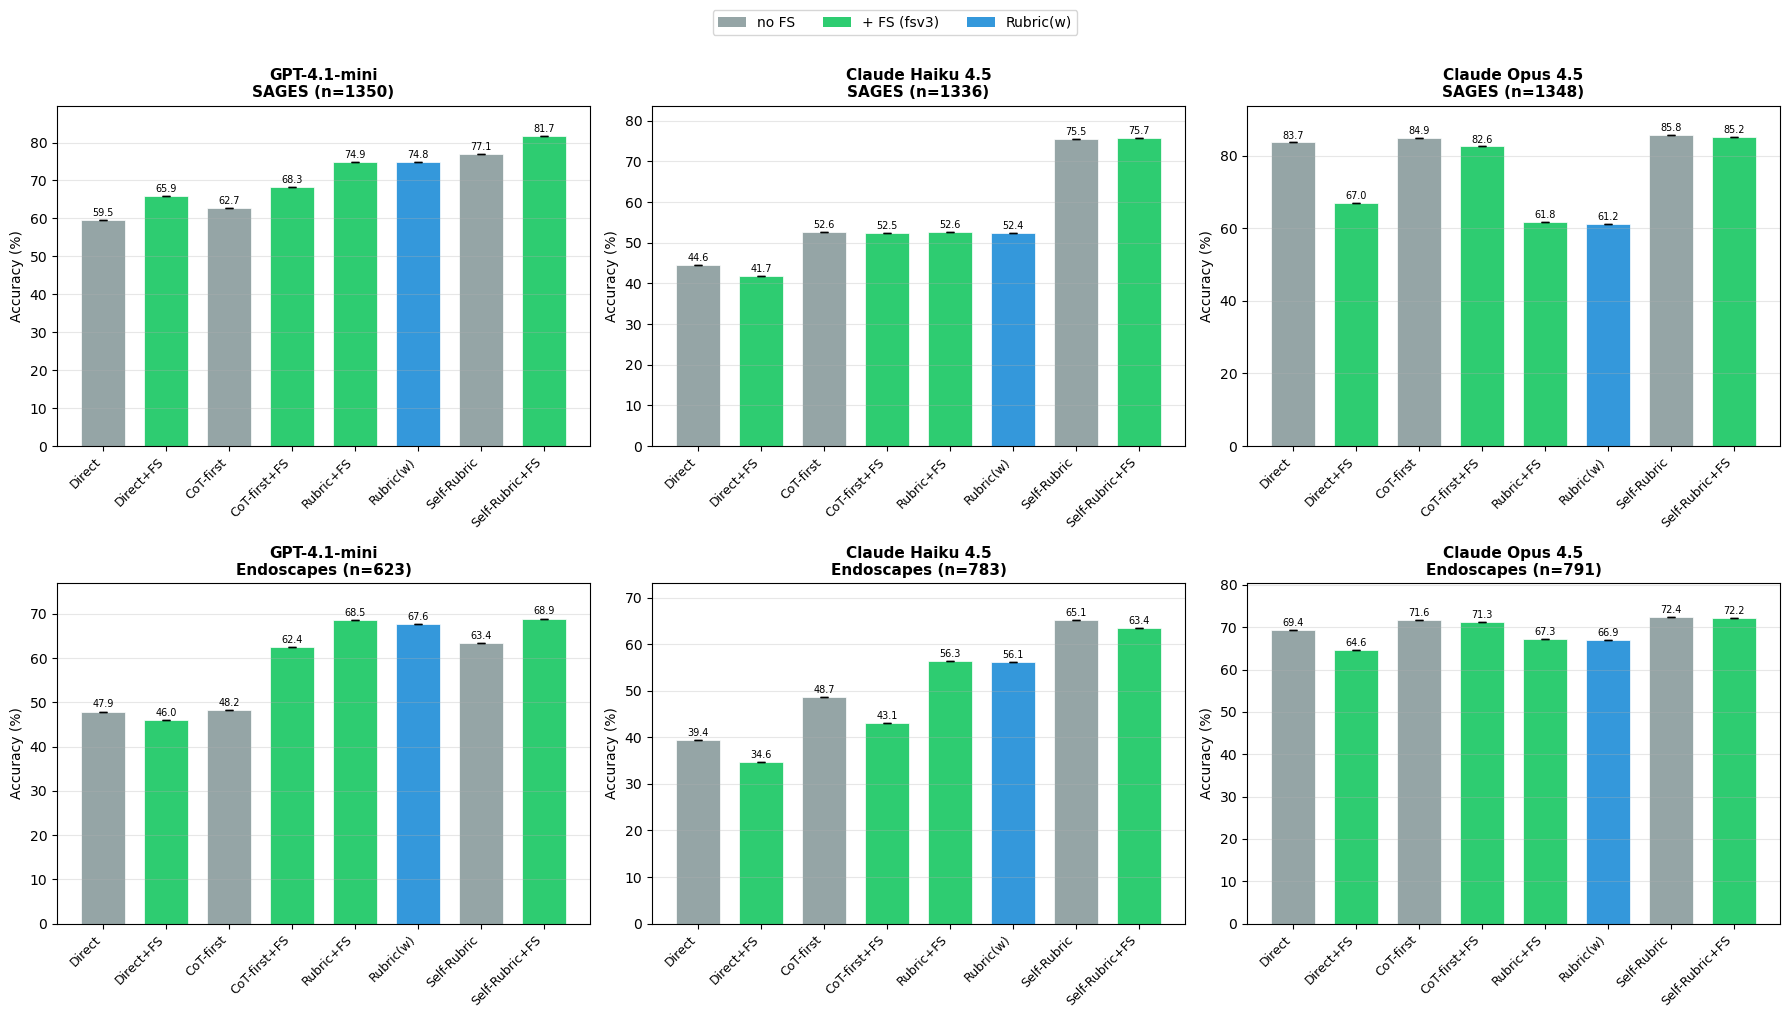

Saved: compact_3models_accuracy.pdf


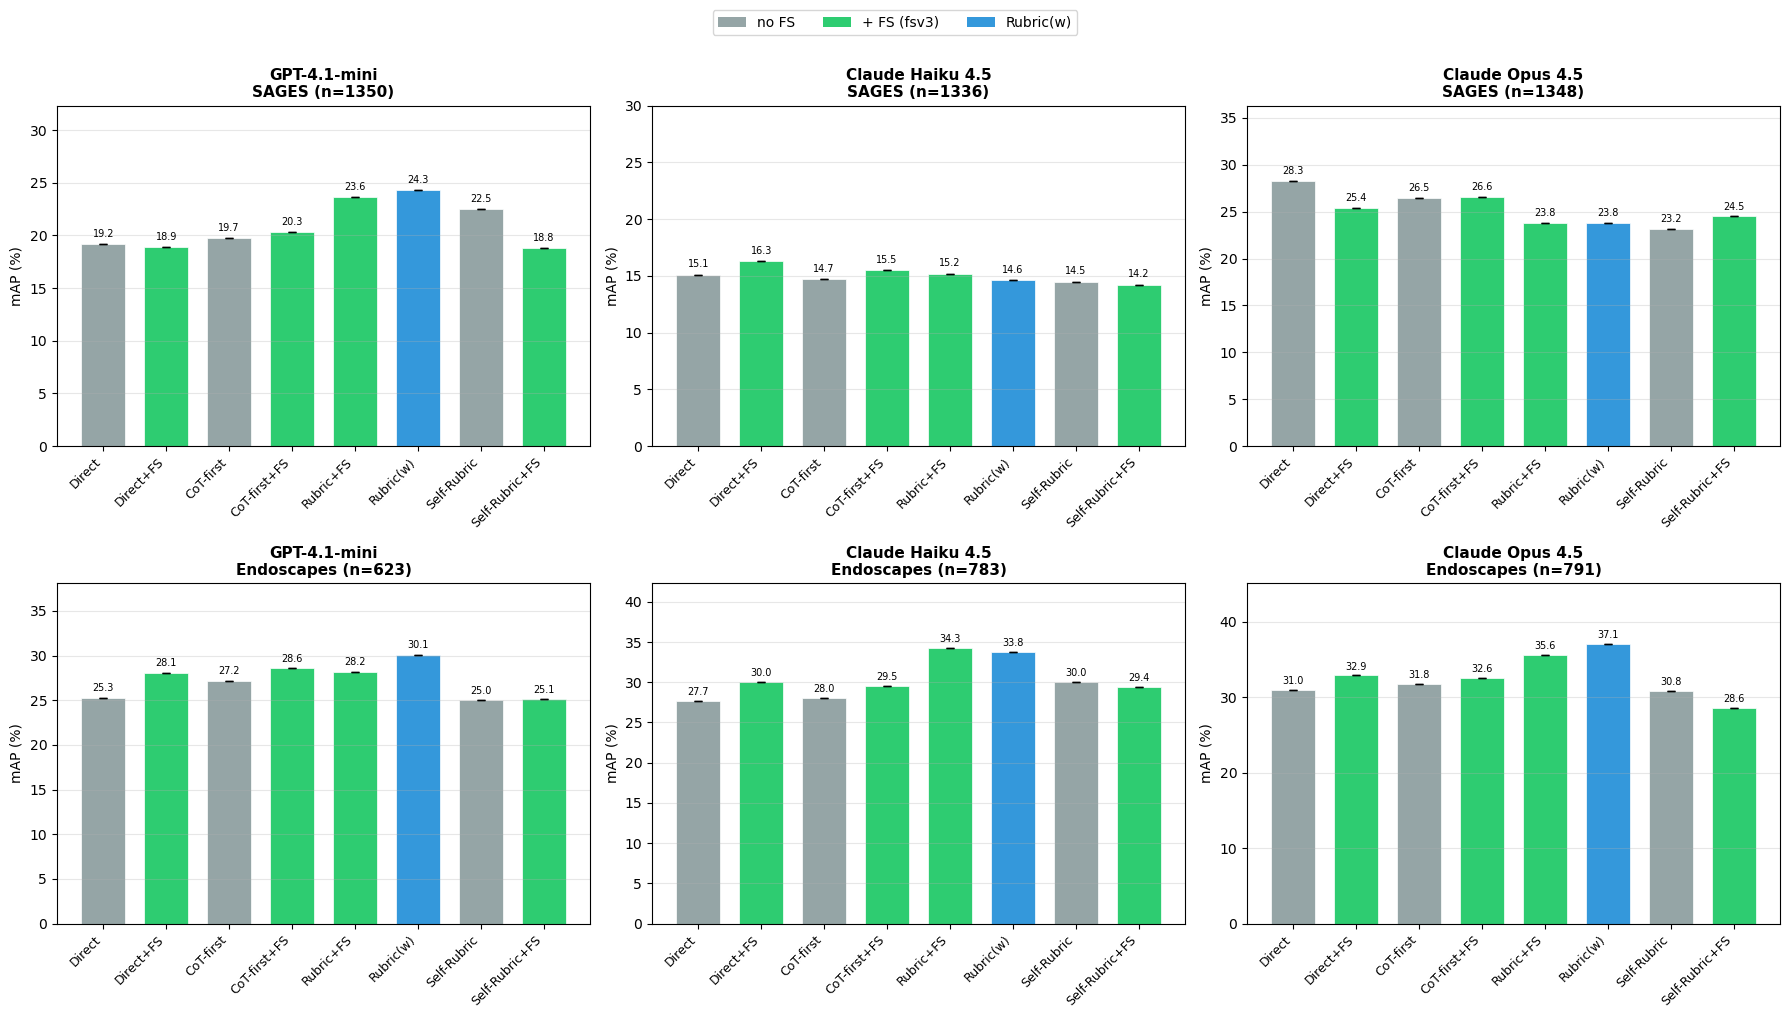

Saved: compact_3models_map.pdf


In [6]:
# ── Compact 2×3 grid: selected methods, 3 models, SAGES + Endoscapes ──

COMPACT_MODELS = [
    ('gpt-4.1-mini',              'GPT-4.1-mini'),
    ('claude-haiku-4-5-20251001', 'Claude Haiku 4.5'),
    ('claude-opus-4-5-20251101',  'Claude Opus 4.5'),
]

COMPACT_DATASETS = [
    ('test_dev_dev', 'SAGES'),
    ('test_dev',     'Endoscapes'),
]

# Each entry: (display_label, source_method_name, column_variant)
# column_variant is 'no FS' or 'fsv3'
COMPACT_METHODS = [
    ('Direct',         'Direct',      'no FS'),
    ('Direct+FS',      'Direct',      'fsv3'),
    ('CoT-first',      'CoT-first',   'no FS'),
    ('CoT-first+FS',   'CoT-first',   'fsv3'),
    ('Rubric+FS',      'Rubric',      'fsv3'),
    ('Rubric(w)',       'Rubric(w)',   'fsv3'),
    ('Self-Rubric',    'Self-Rubric', 'no FS'),
    ('Self-Rubric+FS', 'Self-Rubric', 'fsv3'),
]

# Colors: no-FS methods in grey, FS methods in green
_COMPACT_COLORS = ['#95a5a6', '#2ecc71', '#95a5a6', '#2ecc71',
                   '#2ecc71', '#3498db', '#95a5a6', '#2ecc71']


def _get_compact_value(rows, source_method, variant, metric_key):
    """Extract (mean, std) for a specific method + variant from all_results rows."""
    for r in rows:
        if r['Method'] == source_method:
            return parse_avg(r.get(f'Avg {metric_key} ({variant})', '--'))
    return (float('nan'), 0.0)


def plot_compact_grid(metric_key, metric_label, save_suffix):
    """2×3 bar chart grid: 2 dataset rows × 3 model columns."""
    n_rows = len(COMPACT_DATASETS)
    n_cols = len(COMPACT_MODELS)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows),
                             squeeze=False)

    method_labels = [m[0] for m in COMPACT_METHODS]
    x = np.arange(len(method_labels))

    for col_idx, (model_id, model_name) in enumerate(COMPACT_MODELS):
        for row_idx, (split, dataset_name) in enumerate(COMPACT_DATASETS):
            ax = axes[row_idx][col_idx]
            full_dataset_name = dataset_name
            # Match dataset_name to the key used in all_results
            rows = all_results.get((model_id, full_dataset_name), [])
            if not rows:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                        transform=ax.transAxes, fontsize=12)
                ax.set_title(f'{model_name}\n{dataset_name}',
                             fontsize=11, fontweight='bold')
                ax.set_xticks([])
                continue

            n_ex = _get_n_examples(rows)
            title_suffix = f' (n={n_ex})' if n_ex is not None else ''
            title = f'{model_name}\n{dataset_name}{title_suffix}'

            means, stds = [], []
            for label, src_method, variant in COMPACT_METHODS:
                m, s = _get_compact_value(rows, src_method, variant, metric_key)
                means.append(m if m == m else 0)
                stds.append(s)

            bars = ax.bar(x, means, 0.7, yerr=stds, color=_COMPACT_COLORS,
                          capsize=3, edgecolor='white', linewidth=0.5)

            for b in bars:
                h = b.get_height()
                if h > 0:
                    ax.text(b.get_x() + b.get_width() / 2, h + 0.5,
                            f'{h:.1f}', ha='center', va='bottom', fontsize=7)

            ax.set_xticks(x)
            ax.set_xticklabels(method_labels, rotation=45, ha='right', fontsize=9)
            ax.set_ylabel(metric_label, fontsize=10)
            ax.set_title(title, fontsize=11, fontweight='bold')
            ax.grid(axis='y', alpha=0.3)
            all_vals = [m + s for m, s in zip(means, stds)]
            y_max = max(all_vals) + 8 if any(v > 0 for v in means) else 30
            ax.set_ylim(0, max(y_max, 30))

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#95a5a6', label='no FS'),
                       Patch(facecolor='#2ecc71', label='+ FS (fsv3)'),
                       Patch(facecolor='#3498db', label='Rubric(w)')]
    fig.legend(handles=legend_elements, loc='upper center',
               ncol=3, fontsize=10, frameon=True,
               bbox_to_anchor=(0.5, 1.02))

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    pdf_name = f'compact_3models_{save_suffix}.pdf'
    plt.savefig(REPO_ROOT / 'notebooks' / 'rubrics' / pdf_name,
                bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: {pdf_name}')


display(HTML('<h1>Compact: 3 Models × 2 Datasets (Selected Methods)</h1>'))
plot_compact_grid('Acc', 'Accuracy (%)', 'accuracy')
plot_compact_grid('AP', 'mAP (%)', 'map')

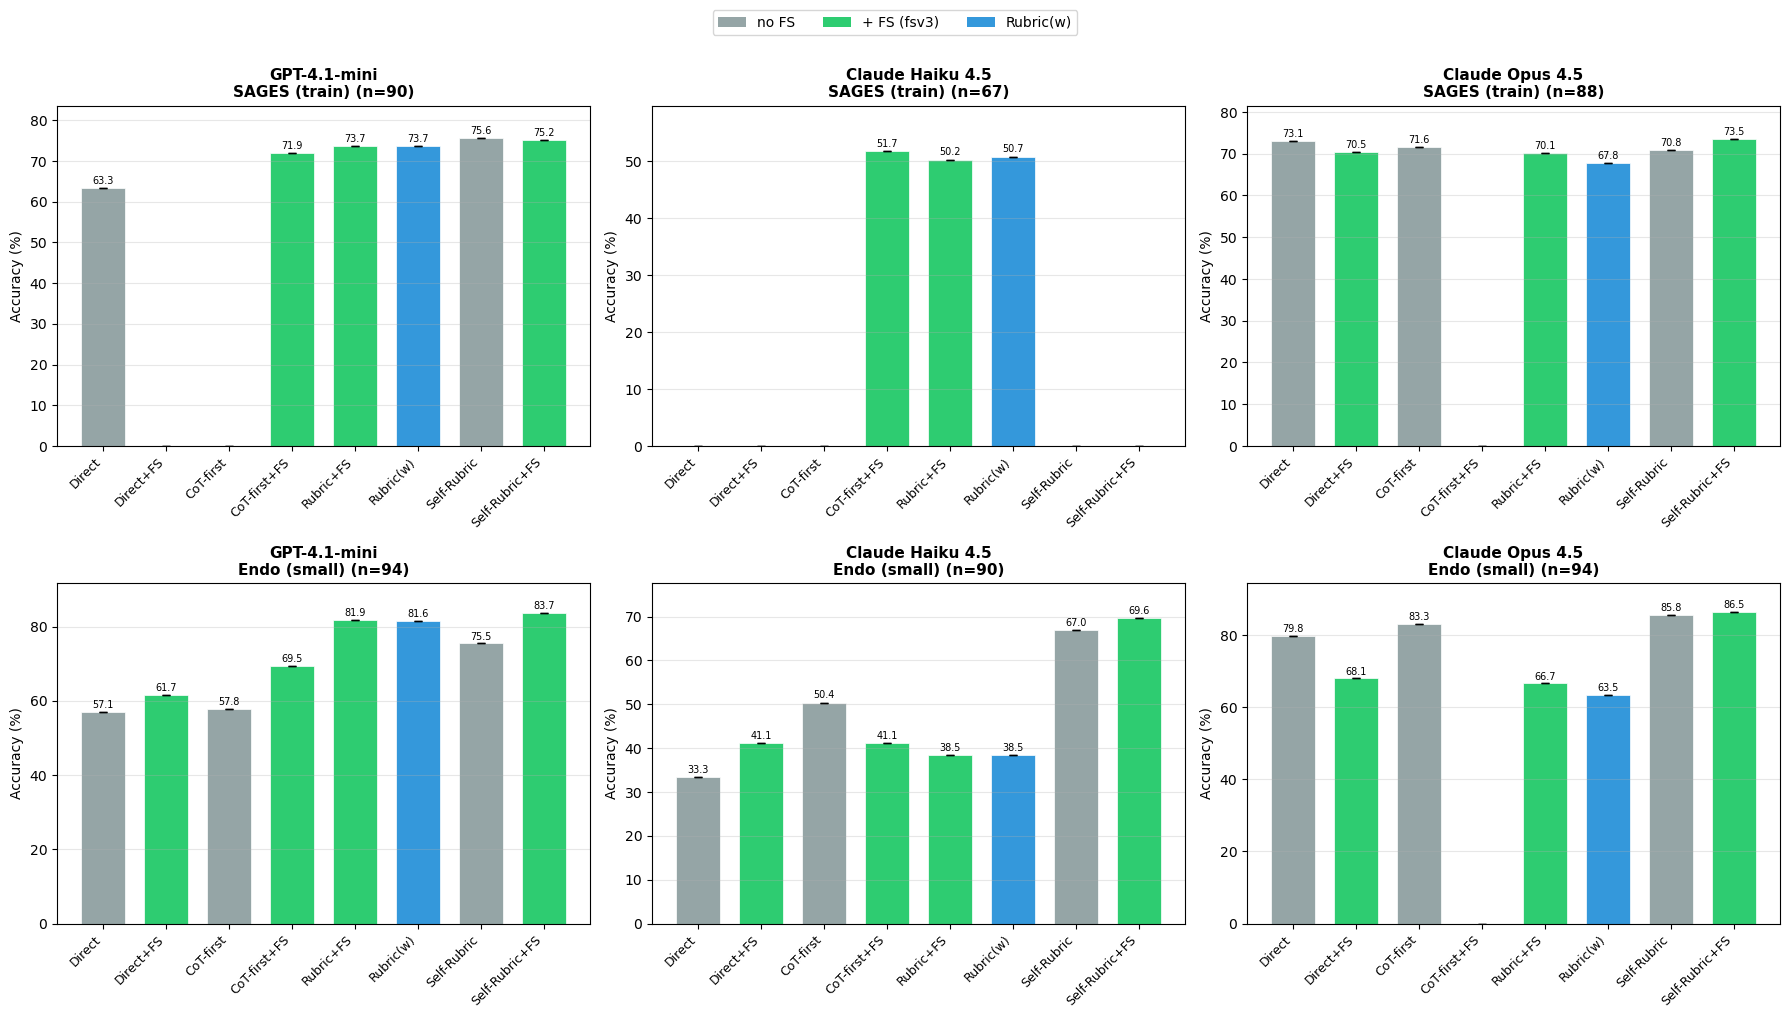

Saved: compact_3models_small_accuracy.pdf


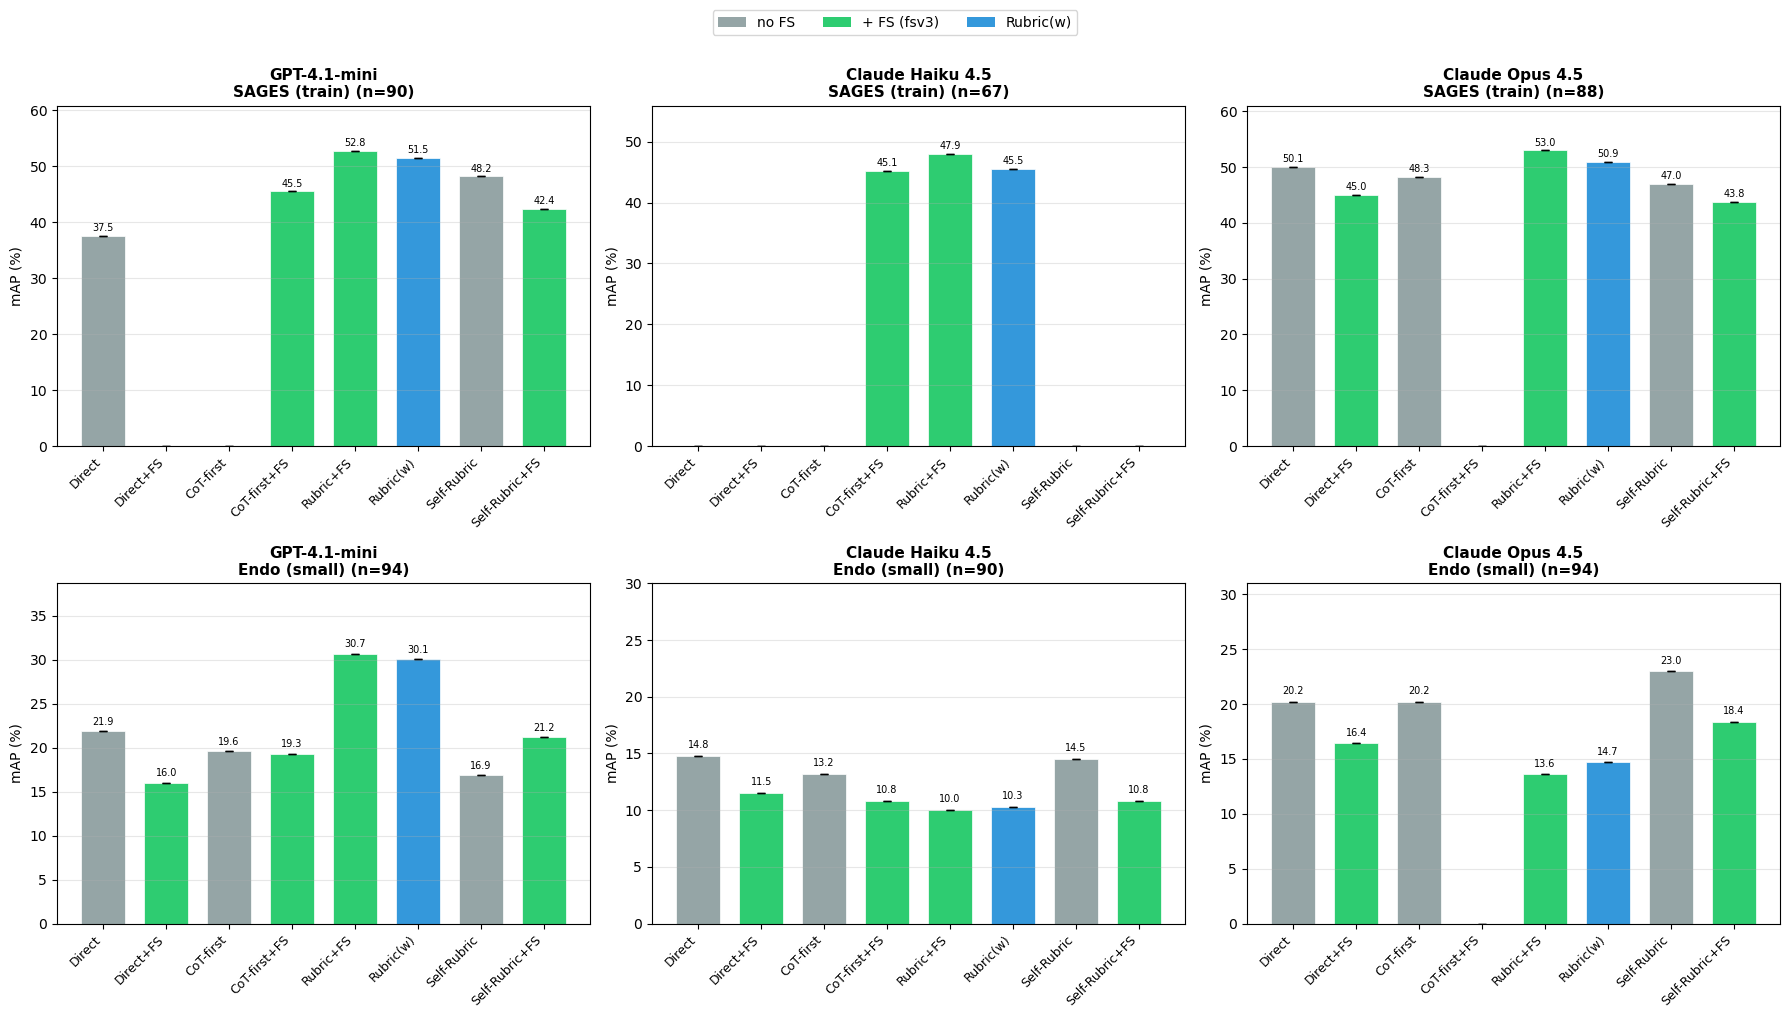

Saved: compact_3models_small_map.pdf


In [7]:
# ── Compact 2×3 grid: small splits (train_dev5 + val_dev_small) ──

COMPACT_DATASETS_SMALL = [
    ('train_dev5',    'SAGES (train)'),
    ('val_dev_small', 'Endo (small)'),
]


def plot_compact_grid_small(metric_key, metric_label, save_suffix):
    """2×3 bar chart grid: 2 small-dataset rows × 3 model columns."""
    n_rows = len(COMPACT_DATASETS_SMALL)
    n_cols = len(COMPACT_MODELS)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows),
                             squeeze=False)

    method_labels = [m[0] for m in COMPACT_METHODS]
    x = np.arange(len(method_labels))

    for col_idx, (model_id, model_name) in enumerate(COMPACT_MODELS):
        for row_idx, (split, dataset_name) in enumerate(COMPACT_DATASETS_SMALL):
            ax = axes[row_idx][col_idx]
            rows = all_results.get((model_id, dataset_name), [])
            if not rows:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                        transform=ax.transAxes, fontsize=12)
                ax.set_title(f'{model_name}\n{dataset_name}',
                             fontsize=11, fontweight='bold')
                ax.set_xticks([])
                continue

            n_ex = _get_n_examples(rows)
            title_suffix = f' (n={n_ex})' if n_ex is not None else ''
            title = f'{model_name}\n{dataset_name}{title_suffix}'

            means, stds = [], []
            for label, src_method, variant in COMPACT_METHODS:
                m, s = _get_compact_value(rows, src_method, variant, metric_key)
                means.append(m if m == m else 0)
                stds.append(s)

            bars = ax.bar(x, means, 0.7, yerr=stds, color=_COMPACT_COLORS,
                          capsize=3, edgecolor='white', linewidth=0.5)

            for b in bars:
                h = b.get_height()
                if h > 0:
                    ax.text(b.get_x() + b.get_width() / 2, h + 0.5,
                            f'{h:.1f}', ha='center', va='bottom', fontsize=7)

            ax.set_xticks(x)
            ax.set_xticklabels(method_labels, rotation=45, ha='right', fontsize=9)
            ax.set_ylabel(metric_label, fontsize=10)
            ax.set_title(title, fontsize=11, fontweight='bold')
            ax.grid(axis='y', alpha=0.3)
            all_vals = [m + s for m, s in zip(means, stds)]
            y_max = max(all_vals) + 8 if any(v > 0 for v in means) else 30
            ax.set_ylim(0, max(y_max, 30))

    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#95a5a6', label='no FS'),
                       Patch(facecolor='#2ecc71', label='+ FS (fsv3)'),
                       Patch(facecolor='#3498db', label='Rubric(w)')]
    fig.legend(handles=legend_elements, loc='upper center',
               ncol=3, fontsize=10, frameon=True,
               bbox_to_anchor=(0.5, 1.02))

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    pdf_name = f'compact_3models_small_{save_suffix}.pdf'
    plt.savefig(REPO_ROOT / 'notebooks' / 'rubrics' / pdf_name,
                bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: {pdf_name}')


display(HTML('<h1>Compact (Small Splits): 3 Models × 2 Datasets</h1>'))
plot_compact_grid_small('Acc', 'Accuracy (%)', 'accuracy')
plot_compact_grid_small('AP', 'mAP (%)', 'map')

# Normalize-Side Results (train_dev5 only)

Separate evaluation for experiments run with `--normalize_side 360` and `--normalize_side 480`.
Only GPT-4.1-mini and Claude Opus 4.5.


--- GPT-4.1-mini / SAGES (train) — Original ---
  COMMON: 90 frames (first copy only), kept=90


,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,54.4,58.9,76.7,63.3,90,90/90/90,--,--,--,--,--,--
1,CoT-first,--,--,--,--,--,--,77.8,63.3,74.4,71.9,90,90/90/90
2,Rubric,--,--,--,--,--,--,83.3,61.1,76.7,73.7,90,90/90/90
3,Rubric(w),--,--,--,--,--,--,83.3,61.1,76.7,73.7,90,90/90/90
4,Rubric(p),--,--,--,--,--,--,72.2,61.1,76.7,70.0,90,90/90/90
5,Rubric(l2),--,--,--,--,--,--,81.1,63.3,77.8,74.1,90,90/90/90
6,Self-Rubric,78.9,66.7,81.1,75.6,90,90/90/90,83.3,65.6,76.7,75.2,90,90/90/90


,Method,C1 AP (no FS),C2 AP (no FS),C3 AP (no FS),Avg AP (no FS),n_common (no FS),n_total (no FS),C1 AP (fsv3),C2 AP (fsv3),C3 AP (fsv3),Avg AP (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,37.5,52.7,22.3,37.5,90,90/90/90,--,--,--,--,--,--
1,CoT-first,--,--,--,--,--,--,53.9,58.1,24.3,45.5,90,90/90/90
2,Rubric,--,--,--,--,--,--,64.2,62.2,32.0,52.8,90,90/90/90
3,Rubric(w),--,--,--,--,--,--,58.3,60.5,35.7,51.5,90,90/90/90
4,Rubric(p),--,--,--,--,--,--,58.1,61.2,35.7,51.7,90,90/90/90
5,Rubric(l2),--,--,--,--,--,--,37.6,51.5,22.2,37.1,90,90/90/90
6,Self-Rubric,47.0,57.9,39.8,48.2,90,90/90/90,55.1,49.4,22.8,42.4,90,90/90/90



--- GPT-4.1-mini / SAGES (train) — normside 360 ---
  COMMON: 90 frames (first copy only), kept=90


,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,61.1,57.8,78.9,65.9,90,90,54.4,58.9,76.7,63.3,90,90
1,CoT-first,60.0,51.1,80.0,63.7,90,90,61.1,50.0,71.1,60.7,90,90
2,Rubric,--,--,--,--,--,--,81.1,65.6,83.3,76.7,90,90
3,Rubric(w),--,--,--,--,--,--,81.1,65.6,83.3,76.7,90,90
4,Rubric(p),--,--,--,--,--,--,80.0,65.6,83.3,76.3,90,90
5,Rubric(l2),--,--,--,--,--,--,78.9,63.3,80.0,74.1,90,90
6,Self-Rubric,80.0,63.3,77.8,73.7,90,90,81.1,62.2,80.0,74.4,90,90


...

,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,83.6,61.6,75.3,73.5,73,90,80.8,63.0,56.2,66.7,73,74
1,CoT-first,83.6,60.3,74.0,72.6,73,90,83.6,61.6,75.3,73.5,73,90
2,Rubric,--,--,--,--,--,--,74.0,64.4,64.4,67.6,73,90
3,Rubric(w),--,--,--,--,--,--,74.0,65.8,60.3,66.7,73,90
4,Rubric(p),--,--,--,--,--,--,68.5,63.0,60.3,63.9,73,90
5,Rubric(l2),--,--,--,--,--,--,82.2,68.5,75.3,75.3,73,90
6,Self-Rubric,80.8,58.9,74.0,71.2,73,89,83.6,61.6,74.0,73.1,73,90


,Method,C1 AP (no FS),C2 AP (no FS),C3 AP (no FS),Avg AP (no FS),n_common (no FS),n_total (no FS),C1 AP (fsv3),C2 AP (fsv3),C3 AP (fsv3),Avg AP (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,43.0,51.6,39.2,44.6,73,90,54.4,56.9,24.8,45.4,73,74
1,CoT-first,49.9,50.0,40.6,46.8,73,90,50.9,59.0,35.7,48.5,73,90
2,Rubric,--,--,--,--,--,--,44.5,61.0,44.1,49.9,73,90
3,Rubric(w),--,--,--,--,--,--,40.6,59.7,45.1,48.5,73,90
4,Rubric(p),--,--,--,--,--,--,42.9,61.3,46.8,50.3,73,90
5,Rubric(l2),--,--,--,--,--,--,38.7,54.3,43.0,45.3,73,90
6,Self-Rubric,30.4,46.3,30.8,35.8,73,89,45.7,52.9,36.6,45.0,73,90



--- Claude Opus 4.5 / SAGES (train) — normside 480 ---
  COMMON: 89 frames (first copy only), kept=89


,Method,C1 Acc (no FS),C2 Acc (no FS),C3 Acc (no FS),Avg Acc (no FS),n_common (no FS),n_total (no FS),C1 Acc (fsv3),C2 Acc (fsv3),C3 Acc (fsv3),Avg Acc (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,80.9,62.9,77.5,73.8,89,90,74.2,65.2,70.8,70.0,89,89
1,CoT-first,79.8,59.6,77.5,72.3,89,90,78.7,62.9,76.4,72.7,89,90
2,Rubric,--,--,--,--,--,--,74.2,74.2,61.8,70.0,89,90
3,Rubric(w),--,--,--,--,--,--,74.2,74.2,56.2,68.2,89,90
4,Rubric(p),--,--,--,--,--,--,73.0,71.9,56.2,67.0,89,90
5,Rubric(l2),--,--,--,--,--,--,74.2,74.2,80.9,76.4,89,90
6,Self-Rubric,78.7,60.7,78.7,72.7,89,90,78.7,62.9,77.5,73.0,89,90


,Method,C1 AP (no FS),C2 AP (no FS),C3 AP (no FS),Avg AP (no FS),n_common (no FS),n_total (no FS),C1 AP (fsv3),C2 AP (fsv3),C3 AP (fsv3),Avg AP (fsv3),n_common (fsv3),n_total (fsv3)
0,Direct,45.6,58.8,41.2,48.5,89,90,42.0,68.1,24.9,45.0,89,89
1,CoT-first,46.5,55.7,31.5,44.5,89,90,43.2,61.5,38.2,47.7,89,90
2,Rubric,--,--,--,--,--,--,34.0,71.9,43.8,49.9,89,90
3,Rubric(w),--,--,--,--,--,--,34.4,70.6,44.0,49.6,89,90
4,Rubric(p),--,--,--,--,--,--,36.0,71.4,45.4,50.9,89,90
5,Rubric(l2),--,--,--,--,--,--,26.5,62.0,39.6,42.7,89,90
6,Self-Rubric,38.7,47.2,37.8,41.2,89,90,35.0,49.1,32.1,38.7,89,90


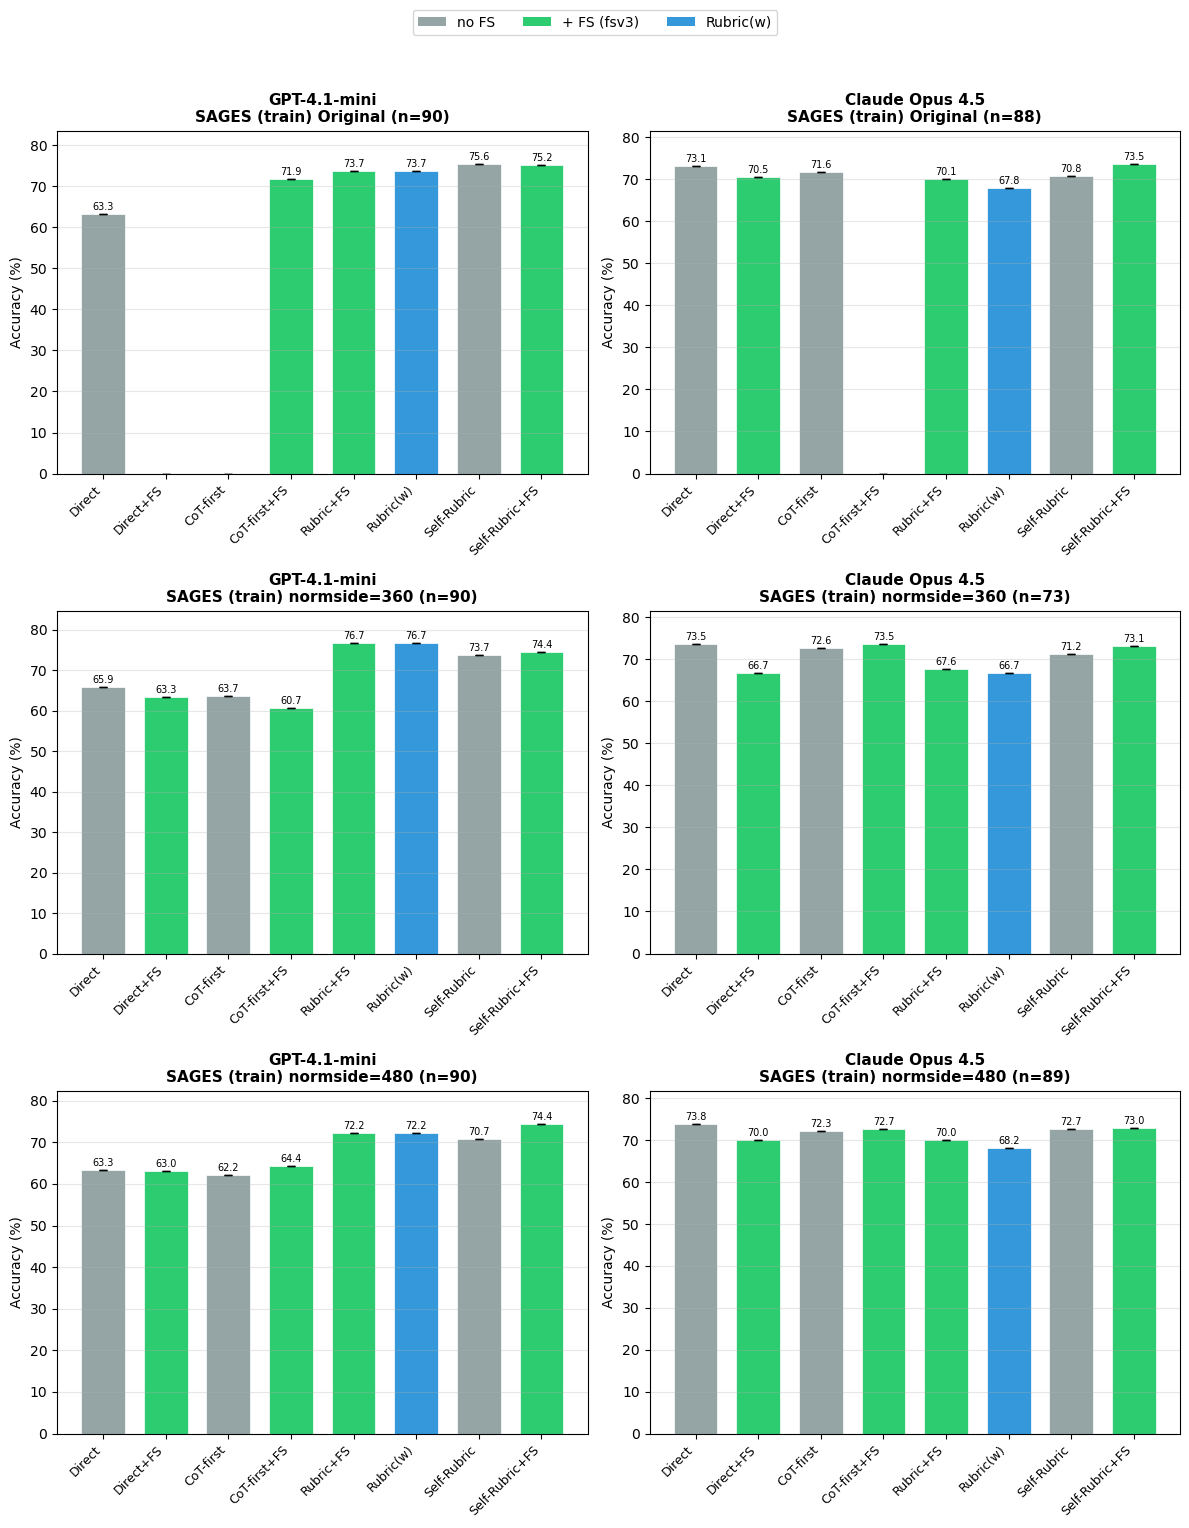

Saved: normside_2models_accuracy.pdf


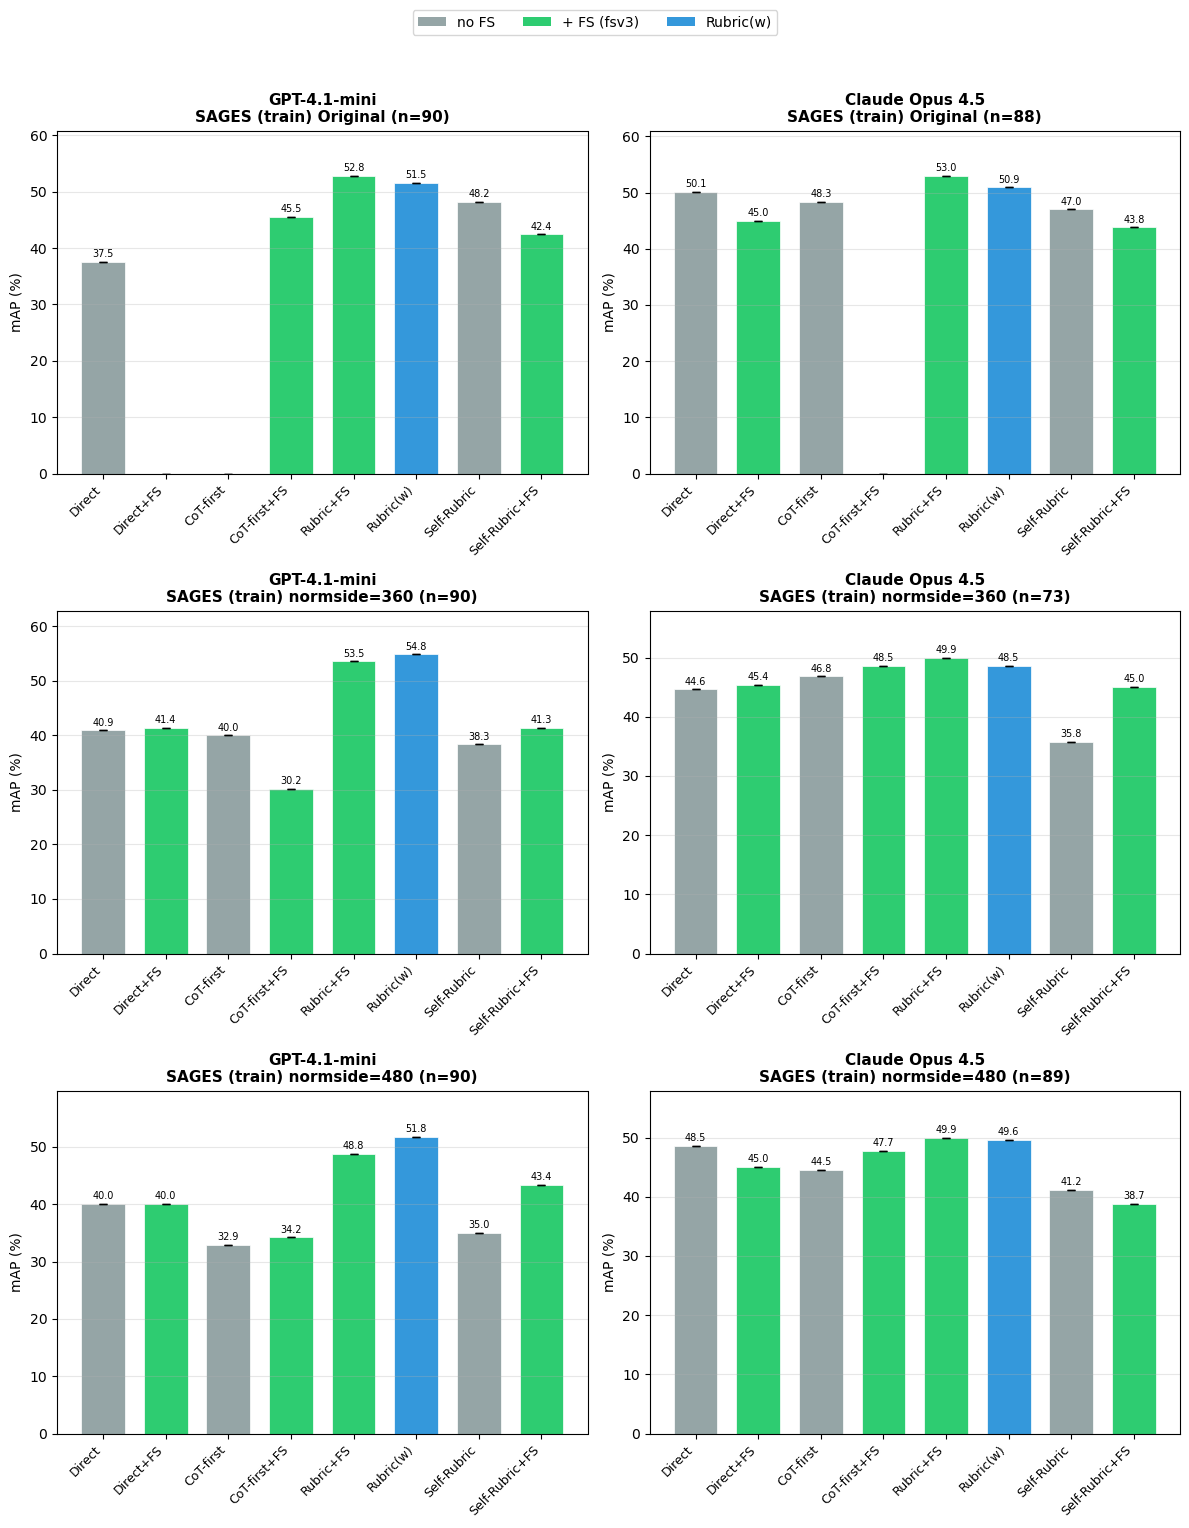

Saved: normside_2models_map.pdf


In [8]:
# ── Normalize-Side evaluation (train_dev5 only, 2 models) ──

NORMSIDE_MODELS = [
    ('gpt-4.1-mini',              'GPT-4.1-mini'),
    ('claude-opus-4-5-20251101',  'Claude Opus 4.5'),
]

NORMSIDES = [360, 480]


def make_method_tuples_normside(split, normside):
    """Method tuples for normside experiments.
    FS labels have ____normside (4 underscores) due to filename insertion."""
    ns = f'normside{normside}'
    rubric_exp = f'predicted_only__{split}__critdef__fsv3__fs4____{ns}'
    return [
        ('Direct',
         f'direct__preset-direct__{split}__critdef__{ns}',
         f'direct__preset-direct__{split}__critdef__fsv3__fs4____{ns}',
         'direct'),
        ('CoT-first',
         f'direct__preset-direct__{split}__critdef__ratdf__{ns}',
         f'direct__preset-direct__{split}__critdef__ratdf__fsv3__fs4____{ns}',
         'direct'),
        ('Rubric',     None, rubric_exp, 'direct'),
        ('Rubric(w)',  None, rubric_exp, 'weighted'),
        ('Rubric(p)',  None, rubric_exp, 'weighted_partial'),
        ('Rubric(l2)', None, rubric_exp, 'last2_product'),
        ('Self-Rubric',
         f'self_rubric__{split}__critdef__rat1__s1short__{ns}',
         f'self_rubric__{split}__critdef__rat1__s1short__fsv3__fs4____{ns}',
         'direct'),
    ]


def make_method_tuples_original(split):
    """Same 7 methods as normside but for the original (unnormalized) experiments."""
    rubric_exp = f'predicted_only__{split}__critdef__fsv3__fs4'
    return [
        ('Direct',
         f'direct__preset-direct__{split}__critdef',
         f'direct__preset-direct__{split}__critdef__fsv3__fs4',
         'direct'),
        ('CoT-first',
         f'direct__preset-direct__{split}__critdef__ratdf',
         f'direct__preset-direct__{split}__critdef__ratdf__fsv3__fs4',
         'direct'),
        ('Rubric',     None, rubric_exp, 'direct'),
        ('Rubric(w)',  None, rubric_exp, 'weighted'),
        ('Rubric(p)',  None, rubric_exp, 'weighted_partial'),
        ('Rubric(l2)', None, rubric_exp, 'last2_product'),
        ('Self-Rubric',
         f'self_rubric__{split}__critdef__rat1__s1short',
         f'self_rubric__{split}__critdef__rat1__s1short__fsv3__fs4',
         'direct'),
    ]


def _eval_method_tuples(df_src, method_tuples, model_id, model_name, ref_frames, tag_label):
    """Run eval for a set of method tuples, return result rows list."""
    sub = df_src[df_src['model'] == model_id]
    if sub.empty:
        display(HTML(f'<h3>{model_name} — {tag_label}: <i>No data</i></h3>'))
        return []

    print(f'\n--- {model_name} / {tag_label} ---')
    df_f = filter_common_frames(df_src, method_tuples, model_id)

    nan_stat = (float('nan'), float('nan'))
    rows = []
    for mname, nofs_exp, fs_exp, stype in method_tuples:
        row = {'Method': mname}

        # ── no FS ──
        if nofs_exp:
            nc_ap, na_ap, nn = compute_method_stats(df_f, nofs_exp, model_id, stype)
            _, _, nn_total = compute_method_stats(df_src, nofs_exp, model_id, stype)
            nc_acc, na_acc, _ = compute_method_acc_stats(df_f, nofs_exp, model_id, stype)
        else:
            nc_ap = nc_acc = {c: nan_stat for c in CRITS}
            na_ap = na_acc = nan_stat; nn = []; nn_total = []

        for c in CRITS:
            row[f'{c.upper()} AP (no FS)'] = fmt_pct(*nc_ap[c])
            row[f'{c.upper()} Acc (no FS)'] = fmt_pct(*nc_acc[c])
        row['Avg AP (no FS)'] = fmt_pct(*na_ap)
        row['Avg Acc (no FS)'] = fmt_pct(*na_acc)
        row['n_common (no FS)'] = '/'.join(str(x) for x in nn) if nn else '--'
        row['n_total (no FS)'] = '/'.join(str(x) for x in nn_total) if nn_total else '--'

        if (should_blank(row['n_common (no FS)'], row['n_total (no FS)']) or
                should_blank_vs_ref(row['n_total (no FS)'], ref_frames)):
            for c in CRITS:
                row[f'{c.upper()} AP (no FS)'] = '--*'
                row[f'{c.upper()} Acc (no FS)'] = '--*'
            row['Avg AP (no FS)'] = '--*'
            row['Avg Acc (no FS)'] = '--*'

        # ── fsv3 ──
        if fs_exp:
            fc_ap, fa_ap, fn = compute_method_stats(df_f, fs_exp, model_id, stype)
            _, _, fn_total = compute_method_stats(df_src, fs_exp, model_id, stype)
            fc_acc, fa_acc, _ = compute_method_acc_stats(df_f, fs_exp, model_id, stype)
        else:
            fc_ap = fc_acc = {c: nan_stat for c in CRITS}
            fa_ap = fa_acc = nan_stat; fn = []; fn_total = []

        for c in CRITS:
            row[f'{c.upper()} AP (fsv3)'] = fmt_pct(*fc_ap[c])
            row[f'{c.upper()} Acc (fsv3)'] = fmt_pct(*fc_acc[c])
        row['Avg AP (fsv3)'] = fmt_pct(*fa_ap)
        row['Avg Acc (fsv3)'] = fmt_pct(*fa_acc)
        row['n_common (fsv3)'] = '/'.join(str(x) for x in fn) if fn else '--'
        row['n_total (fsv3)'] = '/'.join(str(x) for x in fn_total) if fn_total else '--'

        if (should_blank(row['n_common (fsv3)'], row['n_total (fsv3)']) or
                should_blank_vs_ref(row['n_total (fsv3)'], ref_frames)):
            for c in CRITS:
                row[f'{c.upper()} AP (fsv3)'] = '--*'
                row[f'{c.upper()} Acc (fsv3)'] = '--*'
            row['Avg AP (fsv3)'] = '--*'
            row['Avg Acc (fsv3)'] = '--*'

        rows.append(row)

    df_rows = pd.DataFrame(rows)
    display(HTML(f'<h3>{model_name} — {tag_label}</h3>'))

    acc_cols = ['Method'] + \
        [f'{c.upper()} Acc (no FS)' for c in CRITS] + ['Avg Acc (no FS)'] + \
        ['n_common (no FS)', 'n_total (no FS)'] + \
        [f'{c.upper()} Acc (fsv3)' for c in CRITS] + ['Avg Acc (fsv3)'] + \
        ['n_common (fsv3)', 'n_total (fsv3)']
    display(HTML('<b>Binary Accuracy</b>'))
    display(df_rows[[c for c in acc_cols if c in df_rows.columns]])

    ap_cols = ['Method'] + \
        [f'{c.upper()} AP (no FS)' for c in CRITS] + ['Avg AP (no FS)'] + \
        ['n_common (no FS)', 'n_total (no FS)'] + \
        [f'{c.upper()} AP (fsv3)' for c in CRITS] + ['Avg AP (fsv3)'] + \
        ['n_common (fsv3)', 'n_total (fsv3)']
    display(HTML('<b>mAP</b>'))
    display(df_rows[[c for c in ap_cols if c in df_rows.columns]])

    return rows


# ── Evaluate all variants: Original + normside 360 + normside 480 ──
normside_results = {}  # (model_id, variant_label) -> rows

df_train = all_dfs['SAGES (train)']
ref_frames_train = dataset_ref_frames.get('SAGES (train)', 0)

# Variant labels used as keys and chart row labels
VARIANT_LABELS = ['Original'] + [f'normside={ns}' for ns in NORMSIDES]

for model_id, model_name in NORMSIDE_MODELS:
    # Original (unnormalized)
    mt_orig = make_method_tuples_original('train_dev5')
    normside_results[(model_id, 'Original')] = _eval_method_tuples(
        df_train, mt_orig, model_id, model_name, ref_frames_train,
        'SAGES (train) — Original')

    # Normside variants
    for normside in NORMSIDES:
        mt_ns = make_method_tuples_normside('train_dev5', normside)
        normside_results[(model_id, f'normside={normside}')] = _eval_method_tuples(
            df_train, mt_ns, model_id, model_name, ref_frames_train,
            f'SAGES (train) — normside {normside}')


# ── Compact charts: 3 rows (Original, normside=360, normside=480) × 2 model columns ──

NORMSIDE_COMPACT_METHODS = [
    ('Direct',         'Direct',      'no FS'),
    ('Direct+FS',      'Direct',      'fsv3'),
    ('CoT-first',      'CoT-first',   'no FS'),
    ('CoT-first+FS',   'CoT-first',   'fsv3'),
    ('Rubric+FS',      'Rubric',      'fsv3'),
    ('Rubric(w)',       'Rubric(w)',   'fsv3'),
    ('Self-Rubric',    'Self-Rubric', 'no FS'),
    ('Self-Rubric+FS', 'Self-Rubric', 'fsv3'),
]

_NS_COLORS = ['#95a5a6', '#2ecc71', '#95a5a6', '#2ecc71',
              '#2ecc71', '#3498db', '#95a5a6', '#2ecc71']


def _get_ns_value(rows, source_method, variant, metric_key):
    for r in rows:
        if r['Method'] == source_method:
            return parse_avg(r.get(f'Avg {metric_key} ({variant})', '--'))
    return (float('nan'), 0.0)


def plot_normside_grid(metric_key, metric_label, save_suffix):
    """3×2 grid: variant rows (Original, normside=360, normside=480) × model columns."""
    n_rows = len(VARIANT_LABELS)
    n_cols = len(NORMSIDE_MODELS)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows),
                             squeeze=False)

    method_labels = [m[0] for m in NORMSIDE_COMPACT_METHODS]
    x = np.arange(len(method_labels))

    for col_idx, (model_id, model_name) in enumerate(NORMSIDE_MODELS):
        for row_idx, vlabel in enumerate(VARIANT_LABELS):
            ax = axes[row_idx][col_idx]
            rows = normside_results.get((model_id, vlabel), [])
            if not rows:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                        transform=ax.transAxes, fontsize=12)
                ax.set_title(f'{model_name}\n{vlabel}',
                             fontsize=11, fontweight='bold')
                ax.set_xticks([])
                continue

            n_ex = None
            for r in rows:
                s = r.get('n_common (fsv3)', '--')
                if s and s != '--':
                    n_ex = int(s.split('/')[0])
                    break
            title_suffix = f' (n={n_ex})' if n_ex is not None else ''
            title = f'{model_name}\nSAGES (train) {vlabel}{title_suffix}'

            means, stds = [], []
            for label, src_method, variant in NORMSIDE_COMPACT_METHODS:
                m, s = _get_ns_value(rows, src_method, variant, metric_key)
                means.append(m if m == m else 0)
                stds.append(s)

            bars = ax.bar(x, means, 0.7, yerr=stds, color=_NS_COLORS,
                          capsize=3, edgecolor='white', linewidth=0.5)

            for b in bars:
                h = b.get_height()
                if h > 0:
                    ax.text(b.get_x() + b.get_width() / 2, h + 0.5,
                            f'{h:.1f}', ha='center', va='bottom', fontsize=7)

            ax.set_xticks(x)
            ax.set_xticklabels(method_labels, rotation=45, ha='right', fontsize=9)
            ax.set_ylabel(metric_label, fontsize=10)
            ax.set_title(title, fontsize=11, fontweight='bold')
            ax.grid(axis='y', alpha=0.3)
            all_vals = [m + s for m, s in zip(means, stds)]
            y_max = max(all_vals) + 8 if any(v > 0 for v in means) else 30
            ax.set_ylim(0, max(y_max, 30))

    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#95a5a6', label='no FS'),
                       Patch(facecolor='#2ecc71', label='+ FS (fsv3)'),
                       Patch(facecolor='#3498db', label='Rubric(w)')]
    fig.legend(handles=legend_elements, loc='upper center',
               ncol=3, fontsize=10, frameon=True,
               bbox_to_anchor=(0.5, 1.02))

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    pdf_name = f'normside_2models_{save_suffix}.pdf'
    plt.savefig(REPO_ROOT / 'notebooks' / 'rubrics' / pdf_name,
                bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: {pdf_name}')


display(HTML('<h1>Normalize-Side: 2 Models × 3 Variants (train_dev5)</h1>'))
plot_normside_grid('Acc', 'Accuracy (%)', 'accuracy')
plot_normside_grid('AP', 'mAP (%)', 'map')